# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 35: Análise Exploratória das Frequências LOFAR — LARGE Acertadas × Erradas

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

**Tarefa 1 (reunião de 26/10/2026):** comparar o espectro LOFAR das gravações que os modelos acertam e erram e procurar frequências comuns a cada grupo. Começamos pela classe LARGE, a mais fácil entre os navios. Este notebook cobre o **passo 0** (rótulos de acerto e erro), o **passo (a)** (espectro médio, faixa a faixa) o **passo (b)** (linhas persistentes de cada gravação, pico grave e harmônicos) e o **passo (c)** (a banda grave contra tipo de navio, comprimento, condições de gravação e o mesmo navio em gravações diferentes) e o **passo (d)** (validação em metades de navios: a banda é escolhida numa metade e medida na outra), e uma última seção com o LOFAR de faixas de 1 Hz (**lofar1hz**) para separar banda larga de raias.

**Dados.** LOFAR do pipeline `iara` sem normalização (`data/iara_processed/lofar_bc15…`): log-espectrograma (20·log10 da magnitude) menos o fundo estimado pelo TPSW, com valores abaixo de −0,2 zerados. Cada valor é **quanto a faixa sobe acima do fundo de banda larga local, em dB**. Faixas de 7,8125 Hz de 7,8 Hz a 8 kHz (fs = 16 kHz após decimação 3, nfft = 2048). Para cada gravação usamos o **espectro médio** (média de todas as janelas).

**Cuidados de leitura.**
- A CNN LOFAR recebeu este mesmo LOFAR com normalização L2 por janela (`lofar_c5de…`), que muda a escala de cada janela mas não a forma do espectro.
- O TPSW estima o fundo com uma janela de ±21 faixas (±164 Hz). Nas primeiras faixas ele só tem vizinhos de um lado e usa uma correção de borda; os valores absolutos abaixo de ~150 Hz devem ser lidos com cautela. A **comparação entre grupos** continua válida, porque todos passam pelo mesmo processamento.
- O espectro médio esconde linhas que mudam de frequência de navio para navio: uma "corcova" no espectro médio pode ser a soma de linhas estreitas em frequências diferentes. O passo (b) olha as linhas de cada gravação.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, false_discovery_control
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

CLASSE = 'LARGE'
CLS = dict(enumerate(R.CLASSES)); CID = {v: k for k, v in CLS.items()}
C = CID[CLASSE]
MODELO = 'cnn_lofar'                                    # CNN LOFAR do artigo (test_scripts/cnn_lofar.py)
OUTROS = {'MLP LOFAR': 'mlp_lofar', 'SVM LOFAR': 'svm_nystroem_6000_lofar_elasticnet_l1r0.15'}
LOFAR_DIR = os.path.join(R.ROOT, 'data', 'iara_processed', 'lofar_bc1559516c522e2b993895bf5cb2ac94')
CACHE = os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar_espectro_medio.pkl')

# Eixo de frequência do LOFAR do pipeline (src/iara/processing/analysis.py): fs = 48 kHz / decimação 3 = 16 kHz,
# nfft = 2 * n_pts = 2048, sem o bin DC -> 1024 faixas de 7,8125 Hz, de 7,8 Hz a 8 kHz
FS, NFFT = 16000, 2048
F = (np.arange(1024) + 1) * FS / NFFT

if os.path.exists(CACHE):
    S = pd.read_pickle(CACHE)
else:
    ids = sorted(int(f[:-4]) for f in os.listdir(LOFAR_DIR) if f.endswith('.pkl'))
    S = pd.DataFrame({i: pd.read_pickle(os.path.join(LOFAR_DIR, f'{i}.pkl'))['df'].values.mean(0) for i in ids}).T
    S.index.name = 'ID'; S.to_pickle(CACHE)

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta['Length'], errors='coerce')
meta = meta.set_index(meta.ID.astype(int))
print(f'{len(S)} gravações com LOFAR; {len(F)} faixas de {F[0]:.4f} Hz')

1706 gravações com LOFAR; 1024 faixas de 7.8125 Hz


## 0. Rótulos de acerto e erro

Modelo de referência: a **CNN LOFAR do artigo** (`cnn_lofar`, SP 66,49 ± 1,28). Cada gravação é teste em ~5 dos 10 folds; a taxa de acerto é a fração desses folds em que o voto majoritário acertou. Grupos: **acertada** (acerta em todos), **errada** (erra em todos) e **oscila** (o resto, fica fora do contraste). Para robustez, o grupo de **consenso** exige o mesmo resultado na CNN, no MLP LOFAR e no SVM LOFAR.

In [2]:
def taxa_acerto(exp, c):
    # fração dos folds de teste em que a gravação da classe c foi acertada (voto majoritário por gravação)
    d = pd.concat(R.file_predictions(exp).values()); d = d[d.Target == c]
    t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)
    return t

def grupo(t):
    return np.where(t == 1, 'acertada', np.where(t == 0, 'errada', 'oscila'))

T = pd.DataFrame({'CNN LOFAR': taxa_acerto(MODELO, C), **{k: taxa_acerto(v, C) for k, v in OUTROS.items()}})
T['grupo'] = grupo(T['CNN LOFAR'])
todos = T[['CNN LOFAR'] + list(OUTROS)]
T['consenso'] = np.where((todos == 1).all(1), 'acertada', np.where((todos == 0).all(1), 'errada', 'outro'))
T = T.join(meta[['Ship ID', 'Dataset', 'DETAILED TYPE', 'Length']])

# rótulo verdadeiro de todas as gravações (para os espectros de referência das outras classes)
LAB = pd.concat(R.file_predictions(MODELO).values()).groupby('File').Target.first(); LAB.index = LAB.index.astype(int)

# destino dos erros (todas as predições erradas da classe, gravação × fold)
_d = pd.concat(R.file_predictions(MODELO).values()); _d = _d[(_d.Target == C) & (_d.Prediction != C)]
DESTINO = (_d.Prediction.map(CLS).value_counts(normalize=True) * 100).round(1)

CONT = pd.DataFrame({'CNN LOFAR': T.grupo.value_counts(), 'consenso CNN+MLP+SVM': T.consenso.value_counts()}).fillna(0).astype(int)
POR_DS = pd.crosstab(T.Dataset, T.grupo, margins=True, margins_name='total')
POR_DS['% errada'] = (100 * POR_DS['errada'] / POR_DS['total']).round(1)
N_NAVIOS = T['Ship ID'].nunique()
_sh = T[T.grupo != 'oscila'].groupby('Ship ID').grupo.nunique()
N_NAVIOS_MISTOS = int((_sh > 1).sum())
print(f'{CLASSE}: {len(T)} gravações de {N_NAVIOS} navios'); display(CONT)
print('Destino dos erros da CNN LOFAR (%):'); display(DESTINO.to_frame('%'))
print('Grupos por subconjunto de gravação:'); display(POR_DS)
print('Comprimento (m) por grupo:'); display(T.groupby('grupo').Length.describe()[['count', '25%', '50%', '75%']].round(0))

/tmp/ipykernel_64022/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


/tmp/ipykernel_64022/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


LARGE: 572 gravações de 417 navios


/tmp/ipykernel_64022/2548822792.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean()); t.index = t.index.astype(int)


,CNN LOFAR,consenso CNN+MLP+SVM
acertada,346,313
errada,117,72
oscila,109,0
outro,0,187


Destino dos erros da CNN LOFAR (%):


,%
Prediction,
SMALL,49.9
MEDIUM,42.0
BACKGROUND,8.1


Grupos por subconjunto de gravação:


grupo,acertada,errada,oscila,total,% errada
Dataset,,,,,
A,159,24,40,223,10.8
B,6,18,12,36,50.0
C,124,15,23,162,9.3
D,57,60,34,151,39.7
total,346,117,109,572,20.5


Comprimento (m) por grupo:


,count,25%,50%,75%
grupo,,,,
acertada,346.0,183.0,244.0,292.0
errada,117.0,177.0,198.0,290.0
oscila,109.0,180.0,214.0,290.0


**Leitura.**
- 572 gravações LARGE de 417 navios: 346 acertadas, 109 oscilam e 117 erradas. No consenso dos três modelos: 313 acertadas e 72 erradas.
- Destino dos erros: SMALL 49,9%, MEDIUM 42,0%, BACKGROUND 8,1%.
- **O erro não se distribui igualmente entre os subconjuntos:** a fração de erradas vai de 9,3% (C) a 50,0% (B). Por isso a Seção 4 repete a comparação dentro de cada subconjunto.

## 1. Espectro LOFAR médio por grupo

Média dos espectros das gravações de cada grupo (faixa sombreada = IC 95% da média) e, tracejadas, as médias das outras classes:

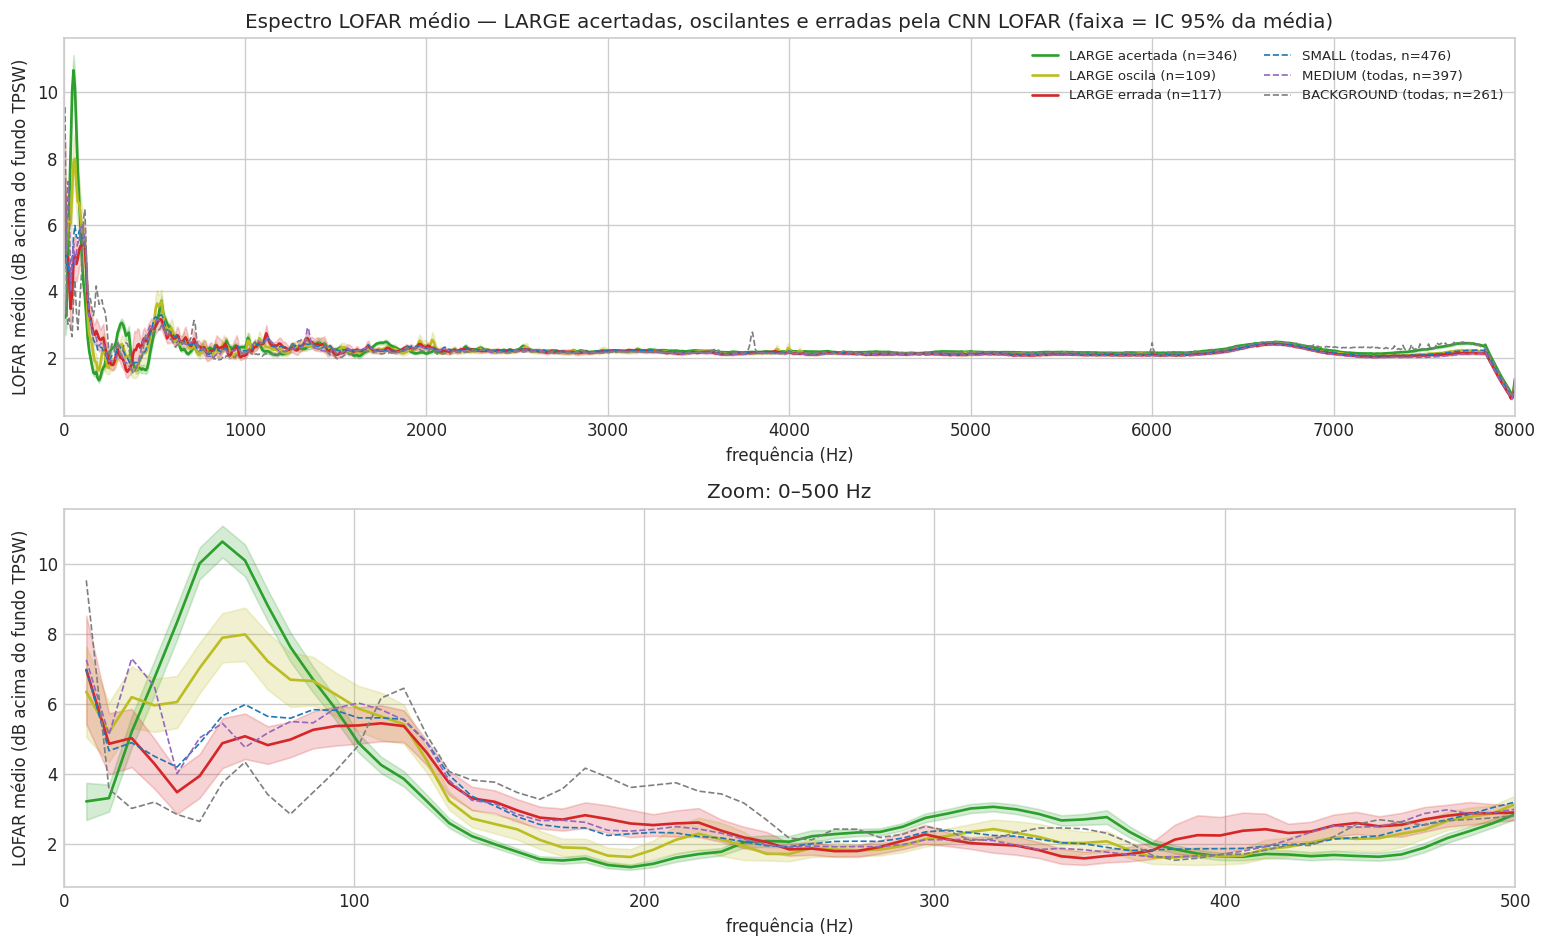

In [3]:
G = {g: S.loc[T.index[T.grupo == g]] for g in ('acertada', 'oscila', 'errada')}
REF = {CLS[c]: S.loc[LAB.index[LAB == c]] for c in range(4) if c != C}
cores = {'acertada': 'tab:green', 'oscila': 'tab:olive', 'errada': 'tab:red'}
cores_ref = dict(zip(REF, ['tab:blue', 'tab:purple', 'tab:gray']))

fig, ax = plt.subplots(2, 1, figsize=(13, 8))
for a, fmax in zip(ax, (8000, 500)):
    k = F <= fmax
    for g, X in G.items():
        m, se = X.mean().values, X.std().values / np.sqrt(len(X))
        a.plot(F[k], m[k], color=cores[g], lw=1.6, label=f'{CLASSE} {g} (n={len(X)})')
        a.fill_between(F[k], (m - 1.96 * se)[k], (m + 1.96 * se)[k], color=cores[g], alpha=0.2)
    for c, X in REF.items():
        a.plot(F[k], X.mean().values[k], color=cores_ref[c], lw=1, ls='--', label=f'{c} (todas, n={len(X)})')
    a.set_xlabel('frequência (Hz)'); a.set_ylabel('LOFAR médio (dB acima do fundo TPSW)')
    a.set_xlim(0, fmax)
ax[0].set_title(f'Espectro LOFAR médio — {CLASSE} acertadas, oscilantes e erradas pela CNN LOFAR (faixa = IC 95% da média)')
ax[1].set_title('Zoom: 0–500 Hz'); ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

## 2. Diferença faixa a faixa

Em cada uma das 1024 faixas, Mann-Whitney entre erradas e acertadas. Para um navio com várias gravações não pesar mais, cada navio entra com a média das suas gravações em cada grupo (276 navios com gravações acertadas e 102 com erradas; 17 navios têm gravações nos dois grupos). Os p-valores são corrigidos pelo FDR de Benjamini-Hochberg. **AUC** = probabilidade de uma gravação errada ter valor maior que uma acertada naquela faixa (0,5 = sem diferença).

Navios: 276 com gravações acertadas, 102 com erradas; 779 de 1024 faixas com q < 0,05


,faixas,"sig. (q < 0,05)",sig. com errada > acertada,sig. com errada < acertada,Δ médio (dB),maior |Δ| (dB)
banda (Hz),,,,,,
0–100,12,9,1,8,-2.55,6.40
100–200,13,12,12,0,1.24,1.58
200–500,38,32,17,15,0.09,1.09
500–1000,64,31,11,20,-0.02,0.55
1000–2000,128,65,39,26,0.03,0.38
2000–4000,256,123,11,112,-0.02,0.18
4000–8000,513,507,0,507,-0.09,0.31


Faixas com maior |Δ| entre as significativas:


,f (Hz),acertada,errada,Δ (errada − acertada),AUC,q (FDR),sig
5,46.88,10.35,3.96,-6.40,0.11,0.0,True
6,54.69,10.92,4.89,-6.03,0.14,0.0,True
4,39.06,8.82,3.47,-5.34,0.15,0.0,True
7,62.50,10.29,5.08,-5.21,0.16,0.0,True
8,70.31,8.92,4.85,-4.07,0.20,0.0,True
0,7.81,3.19,6.48,3.29,0.62,0.0,True
3,31.25,7.07,4.14,-2.93,0.30,0.0,True
9,78.12,7.69,5.02,-2.67,0.29,0.0,True
14,117.19,3.78,5.37,1.58,0.71,0.0,True
15,125.00,3.18,4.62,1.44,0.73,0.0,True


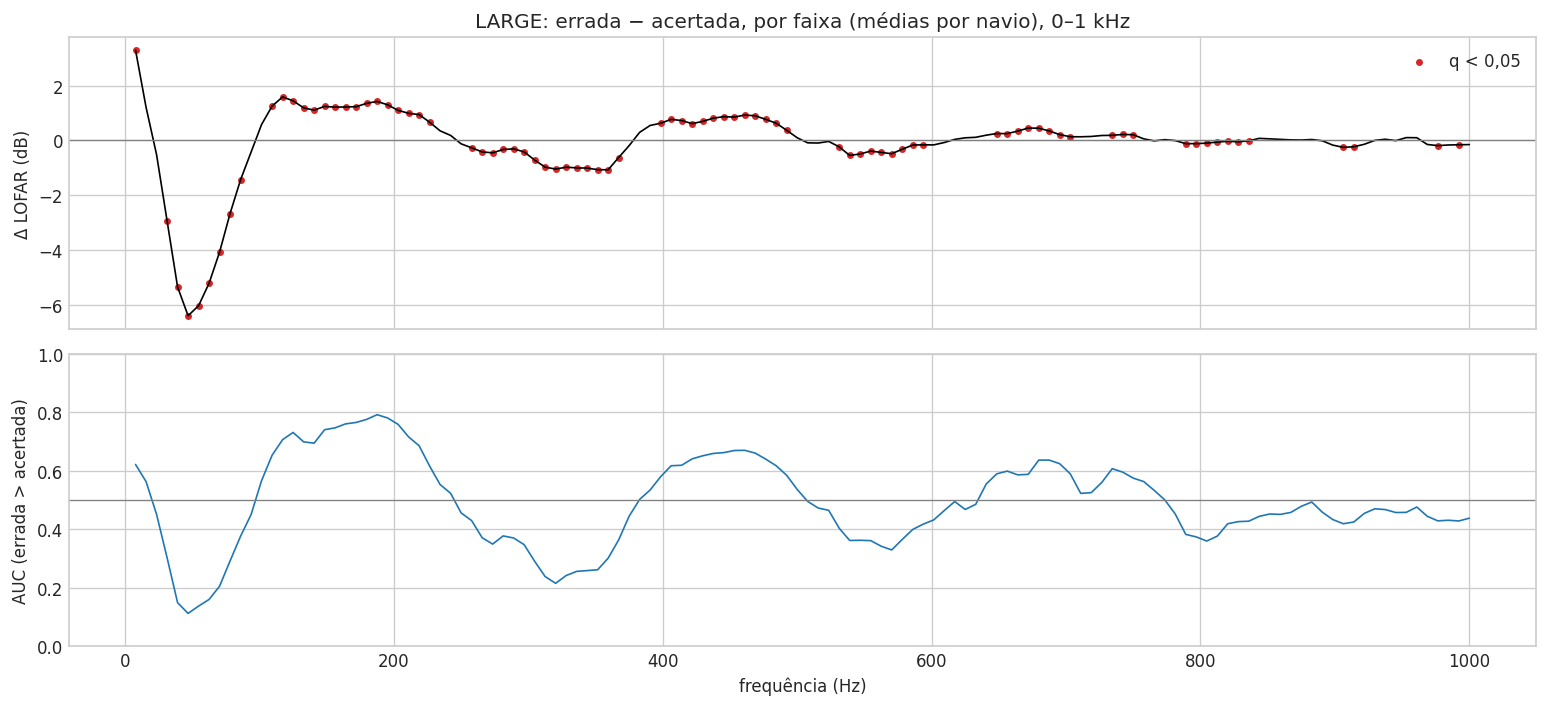

In [4]:
def por_navio(ids):
    # média das gravações de cada navio: cada navio conta uma vez em cada grupo
    return S.loc[ids].groupby(T.loc[ids, 'Ship ID'].values).mean()

def teste_faixas(ids_a, ids_e):
    A, E = por_navio(ids_a), por_navio(ids_e)
    U = np.array([mannwhitneyu(E.iloc[:, k], A.iloc[:, k]).statistic for k in range(S.shape[1])])
    p = np.array([mannwhitneyu(E.iloc[:, k], A.iloc[:, k]).pvalue for k in range(S.shape[1])])
    q = false_discovery_control(p)
    return pd.DataFrame({'f (Hz)': F, 'acertada': A.mean().values, 'errada': E.mean().values,
                         'Δ (errada − acertada)': E.mean().values - A.mean().values,
                         'AUC': U / (len(A) * len(E)), 'q (FDR)': q}), len(A), len(E)

TF, NA, NE = teste_faixas(T.index[T.grupo == 'acertada'], T.index[T.grupo == 'errada'])
TF['sig'] = TF['q (FDR)'] < 0.05

BANDAS = [(0, 100), (100, 200), (200, 500), (500, 1000), (1000, 2000), (2000, 4000), (4000, 8001)]
def resumo_bandas(tf):
    rows = []
    for lo, hi in BANDAS:
        b = tf[(tf['f (Hz)'] >= lo) & (tf['f (Hz)'] < hi)]
        rows.append({'banda (Hz)': f'{lo}–{min(hi, 8000)}', 'faixas': len(b), 'sig. (q < 0,05)': int(b.sig.sum()),
                     'sig. com errada > acertada': int((b.sig & (b['Δ (errada − acertada)'] > 0)).sum()),
                     'sig. com errada < acertada': int((b.sig & (b['Δ (errada − acertada)'] < 0)).sum()),
                     'Δ médio (dB)': b['Δ (errada − acertada)'].mean(), 'maior |Δ| (dB)': b['Δ (errada − acertada)'].abs().max()})
    return pd.DataFrame(rows).set_index('banda (Hz)')
RB = resumo_bandas(TF)
print(f'Navios: {NA} com gravações acertadas, {NE} com erradas; {int(TF.sig.sum())} de {len(TF)} faixas com q < 0,05')
display(RB.round(2))
print('Faixas com maior |Δ| entre as significativas:')
TOP = TF[TF.sig].reindex(TF[TF.sig]['Δ (errada − acertada)'].abs().sort_values(ascending=False).index).head(12)
display(TOP.round(3))

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
k = F <= 1000
ax[0].plot(F[k], TF['Δ (errada − acertada)'][k], color='k', lw=1)
ax[0].scatter(F[k & TF.sig.values], TF['Δ (errada − acertada)'][k & TF.sig.values], color='tab:red', s=10, label='q < 0,05')
ax[0].axhline(0, color='gray', lw=0.8); ax[0].set_ylabel('Δ LOFAR (dB)'); ax[0].legend()
ax[0].set_title(f'{CLASSE}: errada − acertada, por faixa (médias por navio), 0–1 kHz')
ax[1].plot(F[k], TF['AUC'][k], color='tab:blue', lw=1); ax[1].axhline(0.5, color='gray', lw=0.8)
ax[1].set_ylabel('AUC (errada > acertada)'); ax[1].set_xlabel('frequência (Hz)'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

**Leitura.**
- 779 das 1024 faixas têm q < 0,05. Com 276 e 102 navios, diferenças pequenas já são significativas; o que importa é **onde** está o Δ e o seu tamanho.
- **A maior diferença está em 31,2–85,9 Hz:** nas LARGE acertadas o LOFAR médio tem uma corcova com pico em 54,7 Hz (10,7 dB acima do fundo), que quase desaparece nas erradas (4,9 dB). O maior Δ é -6,4 dB em 46,9 Hz (AUC = 0,11).
- **Logo acima, o sinal se inverte:** as erradas têm mais conteúdo acima do fundo em ~100–250 Hz (maior Δ positivo entre 90 Hz e 1 kHz: +1,58 dB em 117,2 Hz, AUC = 0,71).
- **Segunda região, 250–500 Hz:** maior Δ negativo de -1,07 dB em 359,4 Hz (AUC = 0,30, q < 0,05): as acertadas também têm um pouco mais de conteúdo acima do fundo nessa faixa, num efeito bem menor que o da corcova grave.
- **Acima de 4 kHz** quase todas as faixas são significativas (507 de 513), mas o Δ é pequeno (médio -0,09 dB): as erradas têm um pouco menos de estrutura tonal em alta frequência.

## 3. As erradas se parecem com outra classe?

In [5]:
# As erradas se parecem com a classe para onde vão? Correlação e distância RMS entre espectros médios (0–8 kHz e 0–500 Hz)
rows = []
for g in ('acertada', 'oscila', 'errada'):
    x = G[g].mean().values
    for c, X in REF.items():
        y = X.mean().values
        for nome, k in (('0–8 kHz', F <= 8000), ('0–500 Hz', F <= 500)):
            rows.append({'grupo': f'{CLASSE} {g}', 'referência': c, 'faixa': nome,
                         'r de Pearson': np.corrcoef(x[k], y[k])[0, 1], 'distância RMS (dB)': np.sqrt(((x[k] - y[k]) ** 2).mean())})
SEM = pd.DataFrame(rows)
display(SEM.pivot_table(index=['faixa', 'grupo'], columns='referência', values='distância RMS (dB)').round(2))

referência               BACKGROUND  MEDIUM  SMALL
faixa    grupo                                    
0–500 Hz LARGE acertada        2.39    1.68   1.53
         LARGE errada          0.88    0.50   0.36
         LARGE oscila          1.66    0.80   0.69
0–8 kHz  LARGE acertada        0.61    0.44   0.39
         LARGE errada          0.26    0.13   0.10
         LARGE oscila          0.44    0.21   0.18

**Leitura.** Em 0–500 Hz, o espectro médio das LARGE erradas está a 0,36 dB (RMS) do de SMALL, contra 1,53 dB das acertadas. As LARGE erradas **parecem, em média, navios de outra classe** na faixa grave, coerente com o destino dos erros.

## 4. Estratificação por subconjunto de gravação

Os subconjuntos A–D do IARA foram gravados em campanhas e condições diferentes, e a fração de erros muda entre eles (Seção 0). Se a diferença de frequência fosse só efeito do subconjunto, ela sumiria dentro de cada um:

In [6]:
# O subconjunto de gravação (A–D: campanhas, locais e equipamentos diferentes) confunde a comparação?
FAIXAS = {'35–75 Hz': (F >= 35) & (F <= 75), '100–200 Hz': (F >= 100) & (F < 200), '4–8 kHz': F >= 4000}
B = pd.DataFrame({n: S.loc[:, k].mean(1) for n, k in FAIXAS.items()})
B['classe'] = LAB.map(CLS); B['Dataset'] = meta.Dataset
print('LOFAR médio por banda, subconjunto e classe (todas as gravações):')
display(B.groupby(['Dataset', 'classe'])[list(FAIXAS)].mean().round(2).unstack())

L = B.loc[T.index].join(T[['grupo', 'Ship ID']])
rows = []
for ds in sorted(L.Dataset.unique()):
    x = L[L.Dataset == ds]
    a = x[x.grupo == 'acertada'].groupby('Ship ID')[list(FAIXAS)].mean()
    e = x[x.grupo == 'errada'].groupby('Ship ID')[list(FAIXAS)].mean()
    r = {'Dataset': ds, 'navios acertada': len(a), 'navios errada': len(e)}
    for n in FAIXAS:
        r[f'{n}: acertada'] = a[n].mean() if len(a) else np.nan
        r[f'{n}: errada'] = e[n].mean() if len(e) else np.nan
        r[f'{n}: p'] = mannwhitneyu(e[n], a[n]).pvalue if min(len(a), len(e)) >= 5 else np.nan
    rows.append(r)
EST = pd.DataFrame(rows).set_index('Dataset')
print(f'{CLASSE} acertada × errada dentro de cada subconjunto (médias por navio; teste só com ≥ 5 navios por grupo):')
display(EST.round(3))

LOFAR médio por banda, subconjunto e classe (todas as gravações):


35–75 Hz                    100–200 Hz                       4–8 kHz                   
classe  BACKGROUND LARGE MEDIUM SMALL BACKGROUND LARGE MEDIUM SMALL BACKGROUND LARGE MEDIUM SMALL
Dataset                                                                                          
A              NaN  8.48   4.88  4.65        NaN  2.76   3.71  3.76        NaN  2.17   2.07  2.15
B              NaN  5.84   5.00  5.35        NaN  3.08   3.60  3.33        NaN  2.10   2.08  2.10
C              NaN  8.88   5.51  5.41        NaN  2.65   3.57  3.79        NaN  2.19   2.12  2.13
D              NaN  7.21   4.46  5.57        NaN  3.15   3.81  3.53        NaN  2.13   2.07  2.12
E             3.39   NaN    NaN   NaN       4.32   NaN    NaN   NaN        2.2   NaN    NaN   NaN

LARGE acertada × errada dentro de cada subconjunto (médias por navio; teste só com ≥ 5 navios por grupo):


,navios acertada,navios errada,35–75 Hz: acertada,35–75 Hz: errada,35–75 Hz: p,100–200 Hz: acertada,100–200 Hz: errada,100–200 Hz: p,4–8 kHz: acertada,4–8 kHz: errada,4–8 kHz: p
Dataset,,,,,,,,,,,
A,134,23,9.62,5.17,0.00e+00,2.48,3.80,0.00,2.19,2.13,1.00e-03
B,6,16,9.68,3.81,1.00e-03,2.82,3.38,0.15,2.14,2.06,3.29e-01
C,115,13,9.91,3.84,0.00e+00,2.40,4.23,0.00,2.22,2.11,0.00e+00
D,53,54,9.83,4.48,0.00e+00,2.58,3.61,0.00,2.18,2.11,0.00e+00


**Leitura.**
- Banda 35–75 Hz, acertada × errada dentro de cada subconjunto (médias por navio): A: 9,6 × 5,2 dB (p < 0,001); B: 9,7 × 3,8 dB (p < 0,001); C: 9,9 × 3,8 dB (p < 0,001); D: 9,8 × 4,5 dB (p < 0,001).
- **A diferença aparece em todos os subconjuntos testados**: não é efeito do subconjunto. O subconjunto muda a **composição** (onde há mais erros, há mais LARGE sem a corcova grave).

## 5. Robustez: consenso dos três modelos LOFAR

In [7]:
# Mesmo teste com os grupos de consenso (os três modelos LOFAR sempre acertam / sempre erram)
TFc, NAc, NEc = teste_faixas(T.index[T.consenso == 'acertada'], T.index[T.consenso == 'errada'])
TFc['sig'] = TFc['q (FDR)'] < 0.05
RBc = resumo_bandas(TFc)
print(f'Consenso: {NAc} navios acertados, {NEc} errados; {int(TFc.sig.sum())} faixas com q < 0,05')
display(RBc.round(2))
R_DELTA = np.corrcoef(TF['Δ (errada − acertada)'], TFc['Δ (errada − acertada)'])[0, 1]
print(f'Correlação entre os perfis Δ(f) da CNN e do consenso: r = {R_DELTA:.3f}')

Consenso: 253 navios acertados, 64 errados; 744 faixas com q < 0,05


,faixas,"sig. (q < 0,05)",sig. com errada > acertada,sig. com errada < acertada,Δ médio (dB),maior |Δ| (dB)
banda (Hz),,,,,,
0–100,12,10,1,9,-3.11,7.94
100–200,13,12,12,0,1.50,1.88
200–500,38,31,17,14,0.15,1.50
500–1000,64,33,13,20,-0.02,0.60
1000–2000,128,44,27,17,0.03,0.56
2000–4000,256,103,9,94,-0.02,0.22
4000–8000,513,511,0,511,-0.10,0.32


Correlação entre os perfis Δ(f) da CNN e do consenso: r = 0.995


**Leitura.** Com os grupos de consenso (253 navios acertados, 64 errados), a correlação do perfil Δ(f) com o da CNN é r = 0,995. O padrão é do **dado**, não de um modelo: os três modelos LOFAR erram as mesmas LARGE, e elas têm o mesmo perfil de frequência.

## 6. (b) Linhas persistentes em cada gravação

O espectro médio de um grupo pode juntar linhas de navios diferentes. Aqui olhamos cada gravação. **Persistência** de uma faixa = fração das janelas da gravação em que ela passa de 6 dB acima do fundo TPSW (só 2,4% das células janela × faixa passam disso). Uma **linha** é um máximo local da persistência com pelo menos 50% das janelas acima do limiar.

In [8]:
from scipy.signal import find_peaks
from scipy.stats import fisher_exact, spearmanr

# Persistência: fração das janelas de cada gravação em que a faixa passa de um limiar (dB acima do fundo TPSW)
PCACHE = os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar_persistencia.pkl')
if os.path.exists(PCACHE):
    PERS = pd.read_pickle(PCACHE)
else:
    _P = {t: {} for t in (3, 6, 9, 12)}
    for i in S.index:
        x = pd.read_pickle(os.path.join(LOFAR_DIR, f'{i}.pkl'))['df'].values
        for t in _P:
            _P[t][i] = (x > t).mean(0)
    PERS = {t: pd.DataFrame(v).T for t, v in _P.items()}; pd.to_pickle(PERS, PCACHE)

TH, PMIN = 6, 0.5   # linha = máximo local da persistência com >= 50% das janelas acima de 6 dB
FRAC_6DB = 100 * float(PERS[6].values.mean())

def linhas(i, th=TH, pmin=PMIN):
    pk, _ = find_peaks(np.r_[0, PERS[th].loc[i].values, 0], height=pmin)
    return pk - 1

BANDAS_L = [0, 31, 86, 200, 500, 1000, 2000, 4000, 8001]
_rows = []
for g in ('acertada', 'oscila', 'errada'):
    ids = T.index[T.grupo == g]
    Ls = np.concatenate([F[linhas(i)] for i in ids])
    _rows.append((pd.cut(pd.Series(Ls), BANDAS_L, right=False).value_counts(sort=False) / len(ids)).rename(g))
NL = pd.DataFrame(_rows)
NL.columns = [f'{a}–{min(b, 8000)} Hz' for a, b in zip(BANDAS_L[:-1], BANDAS_L[1:])]
NL['total'] = NL.sum(1)
print(f'{FRAC_6DB:.1f}% das células (janela × faixa) de todas as gravações passam de 6 dB acima do fundo.')
print('Linhas por gravação, por banda (média do grupo):'); display(NL.round(2))

def tem_linha(i, th, pm, lo=31, hi=86):
    f = F[linhas(i, th, pm)]
    return bool(np.any((f >= lo) & (f < hi)))
SENS = pd.DataFrame([{'limiar (dB)': th, 'persistência mínima': pm,
                      **{f'% {g} com linha em 31–86 Hz': 100 * np.mean([tem_linha(i, th, pm) for i in T.index[T.grupo == g]])
                         for g in ('acertada', 'oscila', 'errada')}}
                     for th, pm in [(3, 0.8), (6, 0.5), (6, 0.8), (9, 0.5), (12, 0.5)]])
print('Sensibilidade ao critério de linha:'); display(SENS.round(1))

2.4% das células (janela × faixa) de todas as gravações passam de 6 dB acima do fundo.
Linhas por gravação, por banda (média do grupo):


,0–31 Hz,31–86 Hz,86–200 Hz,200–500 Hz,500–1000 Hz,1000–2000 Hz,2000–4000 Hz,4000–8000 Hz,total
acertada,0.21,1.12,0.24,0.20,0.17,0.14,0.03,0.01,2.13
oscila,0.49,0.90,0.44,0.28,0.36,0.16,0.13,0.01,2.75
errada,0.49,0.56,0.52,0.36,0.30,0.18,0.00,0.00,2.40


Sensibilidade ao critério de linha:


,limiar (dB),persistência mínima,% acertada com linha em 31–86 Hz,% oscila com linha em 31–86 Hz,% errada com linha em 31–86 Hz
0,3,0.8,89.6,69.7,47.0
1,6,0.5,89.9,69.7,46.2
2,6,0.8,68.2,37.6,20.5
3,9,0.5,72.0,48.6,22.2
4,12,0.5,46.5,30.3,12.0


**Leitura.**
- As gravações têm poucas linhas persistentes (2,1 por gravação nas acertadas e 2,4 nas erradas), quase todas abaixo de 1 kHz.
- **Nas acertadas, a linha típica está em 31–86 Hz** (1,12 por gravação, contra 0,56 nas erradas). Nas erradas, as linhas se espalham: abaixo de 31 Hz (0,49) e em 86–500 Hz (0,88).
- **Critério de linha** (acertada × errada com linha em 31–86 Hz): 3 dB/80%: 90% × 47%; 6 dB/50%: 90% × 46%; 6 dB/80%: 68% × 21%; 9 dB/50%: 72% × 22%; 12 dB/50%: 47% × 12%. A diferença se mantém em todos os critérios; o resultado não depende do limiar escolhido.

### 6.1 Faixas ocupadas, por navio

Para cada faixa, a fração de navios em que ela está ocupada (persistência ≥ 50%) em ao menos uma gravação do grupo; teste exato de Fisher por faixa com FDR:

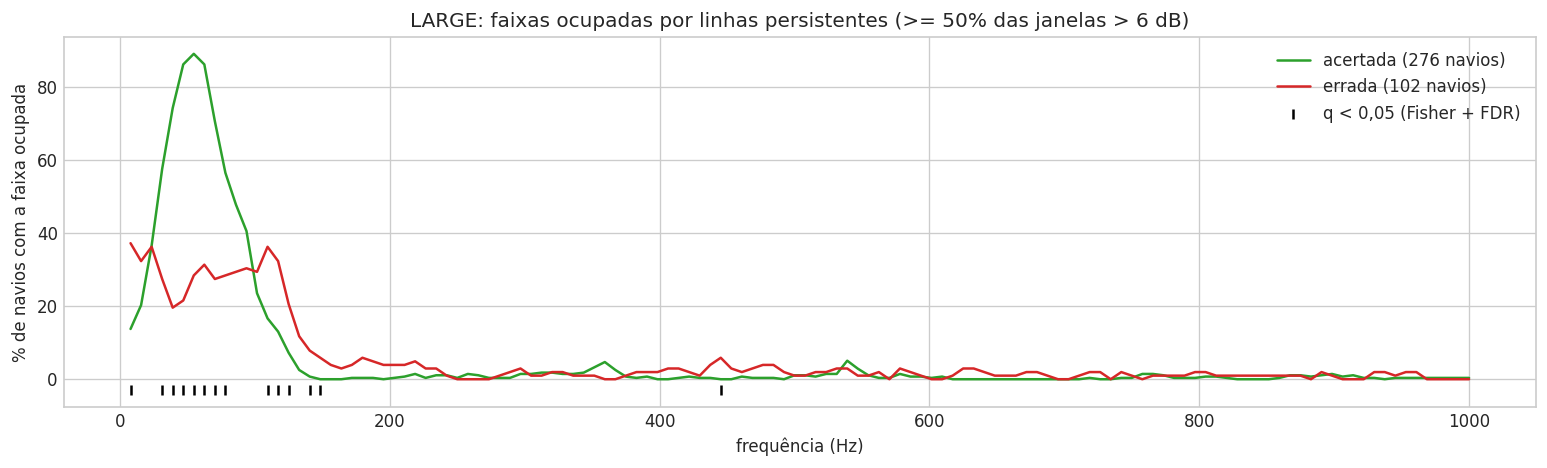

,f (Hz),% navios acertada,% navios errada,q (FDR),sig,"Δ (errada − acertada, p.p.)"
0,7.81,13.77,37.26,0.00e+00,True,23.49
3,31.25,57.61,27.45,0.00e+00,True,-30.16
4,39.06,74.28,19.61,0.00e+00,True,-54.67
5,46.88,86.23,21.57,0.00e+00,True,-64.66
6,54.69,89.13,28.43,0.00e+00,True,-60.70
7,62.50,86.23,31.37,0.00e+00,True,-54.86
8,70.31,70.65,27.45,0.00e+00,True,-43.20
9,78.12,56.52,28.43,0.00e+00,True,-28.09
13,109.38,16.67,36.27,8.00e-03,True,19.61
14,117.19,13.04,32.35,4.00e-03,True,19.31


In [9]:
# Ocupação por faixa: fração de navios com persistência >= 50% naquela faixa (um navio conta se alguma gravação dele tem)
def ocupacao(ids):
    return (PERS[TH].loc[ids] >= PMIN).groupby(T.loc[ids, 'Ship ID'].values).max()
OA, OE = ocupacao(T.index[T.grupo == 'acertada']), ocupacao(T.index[T.grupo == 'errada'])
a, e = OA.sum().values, OE.sum().values
_p = np.array([fisher_exact([[e[k], len(OE) - e[k]], [a[k], len(OA) - a[k]]])[1] for k in range(len(F))])
OCU = pd.DataFrame({'f (Hz)': F, '% navios acertada': 100 * a / len(OA), '% navios errada': 100 * e / len(OE),
                    'q (FDR)': false_discovery_control(_p)})
OCU['sig'] = OCU['q (FDR)'] < 0.05
k = F <= 1000
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(F[k], OCU['% navios acertada'][k], color='tab:green', label=f'acertada ({len(OA)} navios)')
ax.plot(F[k], OCU['% navios errada'][k], color='tab:red', label=f'errada ({len(OE)} navios)')
s = k & OCU.sig.values
ax.scatter(F[s], np.full(s.sum(), -3), marker='|', color='k', label='q < 0,05 (Fisher + FDR)')
ax.set_xlabel('frequência (Hz)'); ax.set_ylabel('% de navios com a faixa ocupada')
ax.set_title(f'{CLASSE}: faixas ocupadas por linhas persistentes (>= {int(100 * PMIN)}% das janelas > {TH} dB)'); ax.legend()
plt.tight_layout(); plt.show()
OCU_SIG = OCU[OCU.sig & (OCU['f (Hz)'] < 1000)].copy()
OCU_SIG['Δ (errada − acertada, p.p.)'] = OCU_SIG['% navios errada'] - OCU_SIG['% navios acertada']
display(OCU_SIG.round(3))

**Leitura.** A maior diferença de ocupação está em 46,9 Hz: 86% dos navios acertados contra 22% dos errados. As faixas mais ocupadas nas acertadas vão de 31 a 78 Hz. Nas erradas, são mais ocupadas as faixas de 109, 117, 125, 141, 148, 445 Hz.

## 7. O pico grave: frequência, altura e largura

Para cada gravação, o **pico grave** é a faixa de maior LOFAR médio entre 20 e 250 Hz. A largura é o trecho contíguo em torno do pico com persistência ≥ 50%. Comparamos também com as outras classes de navio:

Onde cai o pico grave (% das gravações):


LARGE por grupo               todas as gravações, por classe             
                     acertada oscila errada                          LARGE MEDIUM SMALL
faixa do pico                                                                          
20–31 Hz                  4.3   15.6   20.5                            9.8   20.4  16.4
31–86 Hz                 88.2   62.4   34.2                           72.2   35.3  42.9
86–140 Hz                 6.1   14.7   31.6                           12.9   34.8  31.7
140–250 Hz                1.4    7.3   13.7                            5.1    9.6   9.0

Medianas por grupo:


,f pico (Hz),altura (dB),largura (Hz)
grupo,,,
acertada,54.7,12.2,54.7
errada,78.1,9.1,23.4
oscila,62.5,11.0,46.9


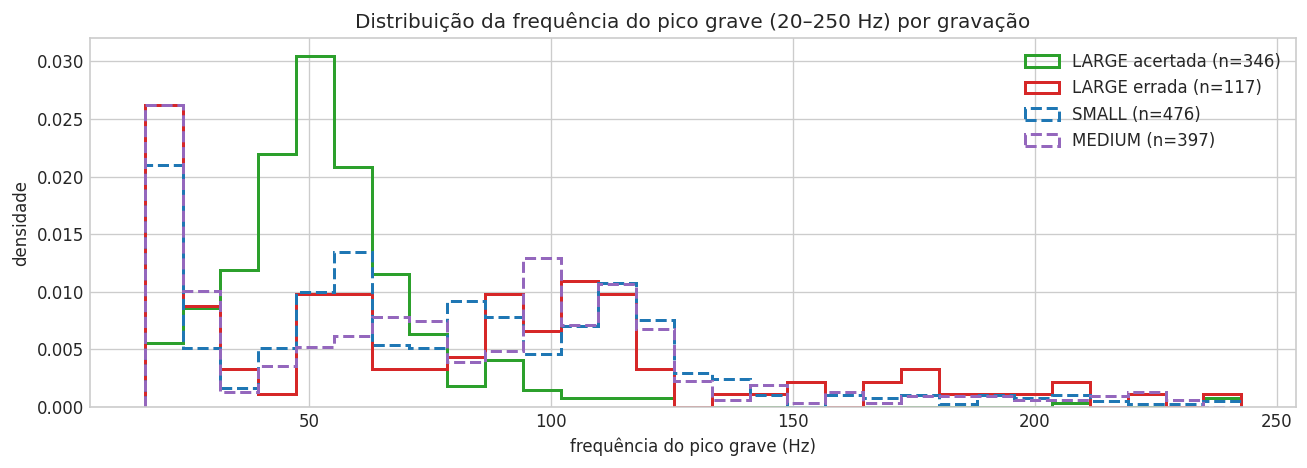

LARGE: rho de Spearman entre frequência do pico e comprimento (por navio, n = 417): -0.202 (p = 3.2e-05)


In [10]:
# Pico grave de cada gravação: faixa de maior LOFAR médio entre 20 e 250 Hz (exclui as 2 primeiras faixas, borda do TPSW)
KP = (F >= 20) & (F <= 250)
_ip = np.where(KP)[0][S.values[:, KP].argmax(1)]
PK = pd.DataFrame({'f pico (Hz)': F[_ip], 'altura (dB)': S.values[np.arange(len(S)), _ip], 'bin': _ip,
                   'classe': LAB.reindex(S.index).map(CLS).values}, index=S.index)
PK = PK.join(meta[['Ship ID', 'Length', 'Dataset']]).join(T[['grupo']])

def largura(i, k):
    # largura (Hz) do trecho contíguo em torno da faixa k com persistência >= PMIN
    p = PERS[TH].loc[i].values
    if p[k] < PMIN:
        return 0.0
    a_, b_ = k, k
    while a_ > 0 and p[a_ - 1] >= PMIN:
        a_ -= 1
    while b_ < len(p) - 1 and p[b_ + 1] >= PMIN:
        b_ += 1
    return (b_ - a_ + 1) * FS / NFFT
PK['largura (Hz)'] = [largura(i, k) for i, k in zip(PK.index, PK['bin'])]

FAIXAS_PICO = [20, 31, 86, 140, 251]
PK['faixa do pico'] = pd.cut(PK['f pico (Hz)'], FAIXAS_PICO, right=False,
                            labels=['20–31 Hz', '31–86 Hz', '86–140 Hz', '140–250 Hz'])
navios = PK[PK.classe != 'BACKGROUND']
DIST_CLASSE = pd.crosstab(navios['faixa do pico'], navios.classe, normalize='columns') * 100
_L = PK.loc[T.index]
DIST_GRUPO = (pd.crosstab(_L['faixa do pico'], _L.grupo, normalize='columns') * 100)[['acertada', 'oscila', 'errada']]
DIST = pd.concat({f'{CLASSE} por grupo': DIST_GRUPO, 'todas as gravações, por classe': DIST_CLASSE}, axis=1)
print('Onde cai o pico grave (% das gravações):'); display(DIST.round(1))
RESUMO_PICO = _L.groupby('grupo')[['f pico (Hz)', 'altura (dB)', 'largura (Hz)']].median()
print('Medianas por grupo:'); display(RESUMO_PICO.round(1))

fig, ax = plt.subplots(figsize=(11, 4))
edges = np.arange(20, 251, FS / NFFT) - FS / NFFT / 2
series = [(f'{CLASSE} acertada', _L[_L.grupo == 'acertada'], 'tab:green', '-'),
          (f'{CLASSE} errada', _L[_L.grupo == 'errada'], 'tab:red', '-')]
series += [(c, navios[navios.classe == c], cor, '--')
           for c, cor in (('SMALL', 'tab:blue'), ('MEDIUM', 'tab:purple'), ('LARGE', 'tab:orange')) if c != CLASSE]
for nome, x, cor, ls in series:
    ax.hist(x['f pico (Hz)'], bins=edges, density=True, histtype='step', lw=1.8, color=cor, ls=ls, label=f'{nome} (n={len(x)})')
ax.set_xlabel('frequência do pico grave (Hz)'); ax.set_ylabel('densidade'); ax.legend()
ax.set_title('Distribuição da frequência do pico grave (20–250 Hz) por gravação'); plt.tight_layout(); plt.show()

# frequência do pico × comprimento do navio, dentro da classe (um ponto por navio)
_n = _L.dropna(subset=['Length']).groupby('Ship ID')[['f pico (Hz)', 'Length']].median()
RHO_LEN = spearmanr(_n['f pico (Hz)'], _n['Length'])
print(f"{CLASSE}: rho de Spearman entre frequência do pico e comprimento (por navio, n = {len(_n)}): "
      f"{RHO_LEN[0]:.3f} (p = {RHO_LEN[1]:.1e})")

**Leitura.**
- **Onde fica o pico:** nas LARGE acertadas, 88% dos picos estão em 31–86 Hz; nas erradas, só 34%, e o resto vai para 20–31 Hz (21%), 86–140 Hz (32%) e 140–250 Hz (14%).
- **As erradas têm o pico onde as outras classes têm:** nas MEDIUM, 35% em 31–86 Hz e 35% em 86–140 Hz e SMALL, 43% em 31–86 Hz e 32% em 86–140 Hz. A distribuição das LARGE erradas é parecida com essas, e não com a das LARGE acertadas. O acúmulo na primeira faixa considerada (23,4 Hz) deve ser lido com cautela: ela está perto da borda inferior do espectro, onde o TPSW só tem vizinhos de um lado; mesmo sem ela, as erradas se concentram fora de 31–86 Hz (86–140 Hz).
- **Não é uma linha estreita:** a largura mediana do pico nas acertadas é 55 Hz (~7 faixas), e a altura mediana é 12,2 dB (9,1 dB nas erradas). É uma **banda de baixa frequência**, estreita o bastante em relação à janela do TPSW (±164 Hz) para sobressair do fundo estimado, e não uma raia tonal de uma faixa. Com faixas de 7,8 Hz, raias estreitas muito próximas também apareceriam como uma banda; o LOFAR do pipeline não as separa.
- **Frequência do pico × tamanho:** dentro das LARGE, o pico fica mais grave quanto maior o navio (ρ de Spearman = -0,20, p < 0,001, um ponto por navio). A relação é fraca, mas tem o sentido esperado: navios maiores, componentes mais graves.

### 7.1 A banda como pista do modelo

Para todas as gravações de navio: em que fração dos folds a CNN LOFAR prevê LARGE, conforme a gravação tenha ou não o pico grave em 31–86 Hz?

In [11]:
# A banda como pista do modelo: em que fração dos folds a gravação é prevista como LARGE, sem e com o pico grave
# (maior LOFAR médio entre 20 e 250 Hz) em 31–86 Hz? Só gravações de navio (sem BACKGROUND).
_kp = (F >= 20) & (F <= 250)
_pk = pd.Series(F[np.where(_kp)[0][S.values[:, _kp].argmax(1)]], index=S.index)
_dd = pd.concat(R.file_predictions(MODELO).values()); _dd['File'] = _dd.File.astype(int)
_t = _dd.assign(L=_dd.Prediction == CID['LARGE']).groupby('File').agg(L=('L', 'mean'), Target=('Target', 'first'))
_t = _t[_t.Target != CID['BACKGROUND']]
_t['banda'] = _pk.reindex(_t.index).between(31, 86, inclusive='left')
_t['classe'] = _t.Target.map(CLS)
BANDA_PREV = (100 * _t.groupby(['classe', 'banda']).L.mean().unstack()).rename(
    columns={False: '% prevista LARGE, sem a banda', True: '% prevista LARGE, com a banda'})
BANDA_PREV.columns.name = None
BANDA_PREV['% das gravações com a banda'] = 100 * _t.groupby('classe').banda.mean()
BANDA_PREV = BANDA_PREV.loc[['SMALL', 'MEDIUM', 'LARGE']]
FRAC_LARGE_BANDA = 100 * (_t[_t.banda].classe == 'LARGE').mean()
display(BANDA_PREV.round(1))
print(f'Das gravações de navio com a banda, {FRAC_LARGE_BANDA:.0f}% são LARGE.')

,"% prevista LARGE, sem a banda","% prevista LARGE, com a banda",% das gravações com a banda
classe,,,
SMALL,11.4,37.1,42.9
MEDIUM,5.9,22.6,35.3
LARGE,39.1,83.2,72.2


Das gravações de navio com a banda, 55% são LARGE.


**Leitura.** **A banda é uma pista importante para o modelo dizer LARGE, mas uma pista fraca de tamanho real.** Em qualquer classe, ter a banda aumenta a chance de a gravação ser chamada de LARGE (SMALL de 11% para 37%; MEDIUM de 6% para 23%; LARGE de 39% para 83%). Não é uma regra: mesmo com a banda, 63% das SMALL e 77% das MEDIUM não são chamadas de LARGE, e as LARGE sem a banda ainda são chamadas de LARGE em 39% dos casos; o modelo usa outras pistas também. O problema é que a banda separa mal as classes reais: aparece em 72% das LARGE, mas também em 43% das SMALL e 35% das MEDIUM, e das gravações com a banda só 55% são LARGE. Usá-la não é irracional (ela aumenta a probabilidade de LARGE), mas é fraca, e parte dos erros vem daí: as SMALL e MEDIUM chamadas de LARGE se concentram nas que têm a banda, e as LARGE chamadas de outra classe, nas que não a têm.

## 8. Harmônicos

Se o pico grave fosse a fundamental de uma máquina (eixo, motor, gerador), esperaríamos linhas nos múltiplos. A **taxa de base** é a chance de encontrar uma linha numa posição qualquer da mesma faixa de frequência, com a mesma tolerância:

In [12]:
# Harmônicos: nas gravações com pico grave em 31–86 Hz, há linha em 2x e 3x a frequência do pico?
# Tolerância de ±h faixas (a incerteza de ±1/2 faixa no pico cresce com o múltiplo). Taxa de base: chance de haver
# linha a <= h faixas de uma posição qualquer da faixa [h·31, h·86] Hz na mesma gravação.
_rows = []
for i in T.index[T.grupo.isin(['acertada', 'errada'])]:
    f0, k0 = PK.loc[i, 'f pico (Hz)'], int(PK.loc[i, 'bin'])
    if not (31 <= f0 < 86):
        continue
    ls = linhas(i)
    for h in (2, 3):
        tgt = h * (k0 + 1) - 1
        cand = np.arange(int(np.ceil(h * 31 / (FS / NFFT))) - 1, int(h * 86 / (FS / NFFT)))
        _rows.append({'grupo': T.grupo[i], 'múltiplo': h,
                      'linha no múltiplo (%)': 100 * any(abs(m - tgt) <= h for m in ls),
                      'taxa de base (%)': 100 * np.mean([any(abs(m - c) <= h for m in ls) for c in cand])})
HARM = pd.DataFrame(_rows).groupby(['grupo', 'múltiplo']).agg(
    gravações=('múltiplo', 'size'), linha_no_multiplo=('linha no múltiplo (%)', 'mean'),
    taxa_de_base=('taxa de base (%)', 'mean')).rename(columns={'linha_no_multiplo': 'linha no múltiplo (%)',
                                                               'taxa_de_base': 'taxa de base (%)'})
display(HARM.round(1))

gravações  linha no múltiplo (%)  taxa de base (%)
grupo    múltiplo                                                    
acertada 2               305                   13.8              20.6
         3               305                    4.3               6.9
errada   2                40                   27.5              28.0
         3                40                    5.0              12.2

**Leitura.** acertada, 2×: 13,8% contra base de 20,6%; acertada, 3×: 4,3% contra base de 6,9%; errada, 2×: 27,5% contra base de 28,0%; errada, 3×: 5,0% contra base de 12,2%. Em nenhum grupo há mais linhas nos múltiplos do que o esperado ao acaso: **não há estrutura harmônica** detectável a partir do pico grave, coerente com ele ser uma banda e não uma fundamental.

## 9. Exemplos

Espectrogramas LOFAR de 0 a 500 Hz de gravações sorteadas do subconjunto A:

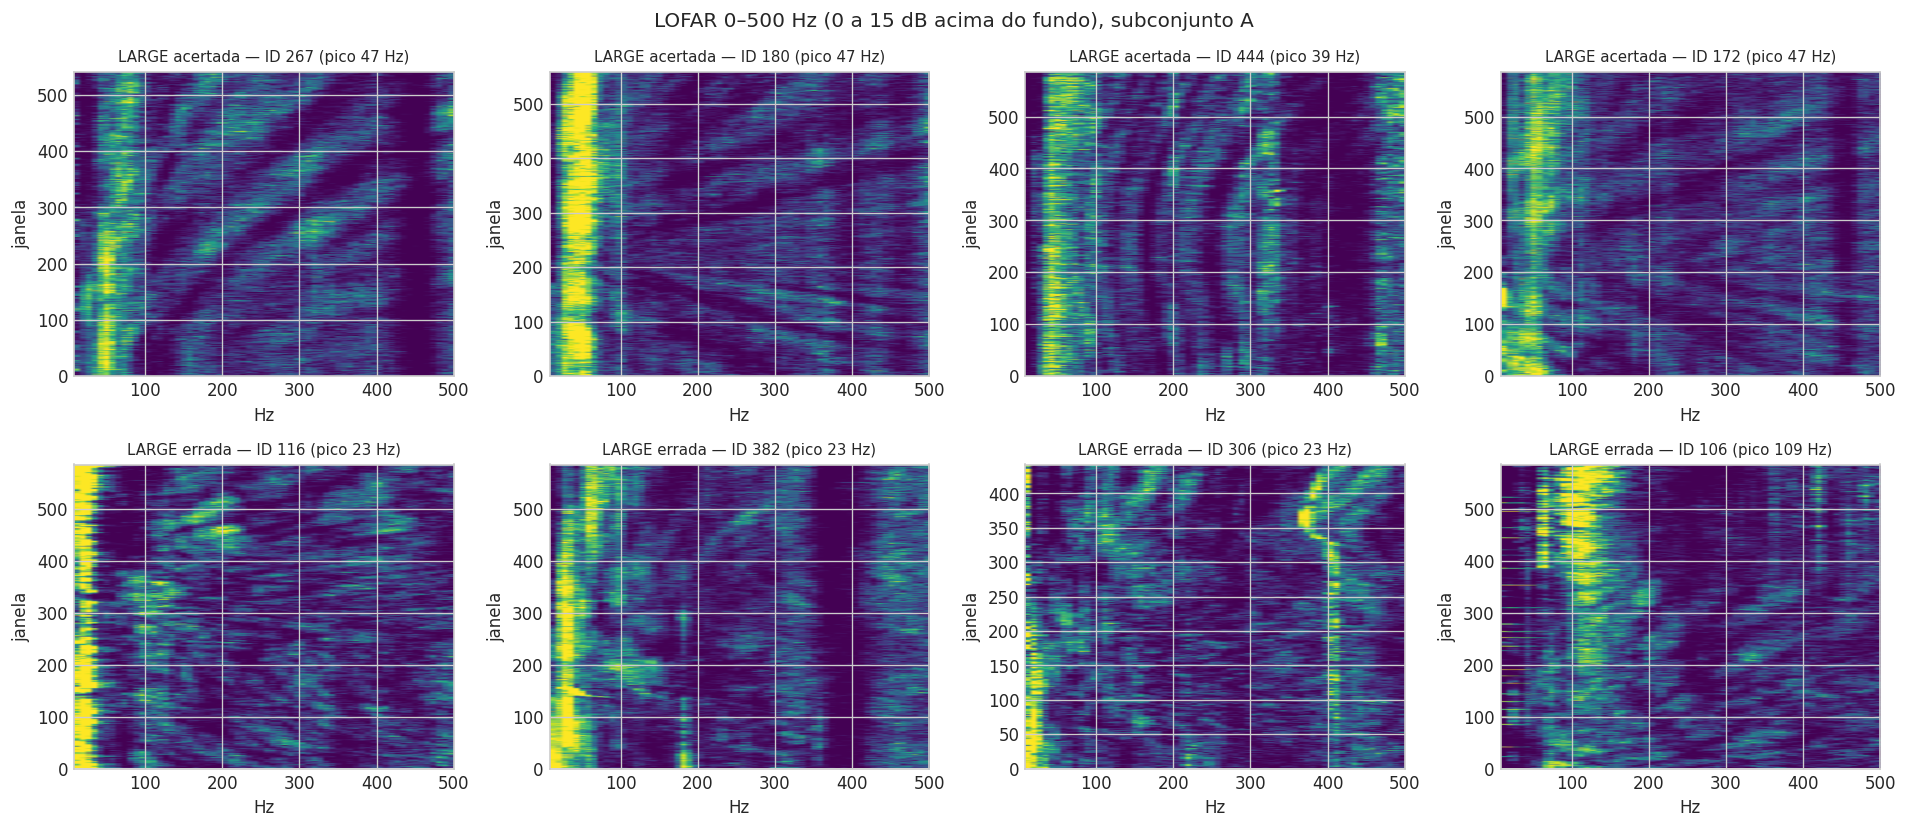

In [13]:
# Espectrogramas LOFAR (0–500 Hz) de gravações sorteadas do subconjunto com mais gravações da classe (semente fixa)
_rng = np.random.default_rng(1)
_ds = T.Dataset.value_counts().index[0]
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for r, g in enumerate(('acertada', 'errada')):
    pool = T.index[(T.grupo == g) & (T.Dataset == _ds)]
    for c, i in enumerate(_rng.choice(pool, min(4, len(pool)), replace=False)):
        x = pd.read_pickle(os.path.join(LOFAR_DIR, f'{i}.pkl'))['df'].values[:, F <= 500]
        ax[r, c].imshow(x, aspect='auto', origin='lower', extent=[F[0], 500, 0, len(x)], vmin=0, vmax=15, cmap='viridis')
        ax[r, c].set_title(f'{CLASSE} {g} — ID {i} (pico {PK.loc[i, "f pico (Hz)"]:.0f} Hz)', fontsize=9)
        ax[r, c].set_xlabel('Hz'); ax[r, c].set_ylabel('janela')
fig.suptitle(f'LOFAR 0–500 Hz (0 a 15 dB acima do fundo), subconjunto {_ds}'); plt.tight_layout(); plt.show()
EXEMPLO_DS = _ds

**Leitura.** Nas acertadas, a banda de ~30–80 Hz aparece como uma faixa vertical clara e estável ao longo da gravação. Nas erradas, a energia grave fica abaixo de ~30 Hz ou acima de ~90 Hz, ou a banda é fraca. As listras diagonais e curvas que aparecem nos dois grupos parecem padrões de interferência que mudam com a distância do navio durante a passagem (não verificado aqui); a olho, elas não separam os grupos.

## 10. (c) A banda grave depende do navio ou da gravação?

Nesta seção, uma gravação **tem a banda** quando o seu pico grave (Seção 7) cai em 31–86 Hz. Cruzamos a banda e o grupo (acertada × errada) com o tipo de navio, o comprimento e as condições registradas no `iara.csv` (vento em m/s, estado do mar, chuva). O IARA não registra velocidade nem regime de máquinas, as variáveis físicas mais prováveis para a banda.

### 10.1 Tipo de navio

Tipos com pelo menos 10 gravações acertadas ou erradas, ordenados pela fração de erradas:

In [14]:
from scipy.stats import binomtest
# Tabela por gravação (só acertadas e erradas): banda = pico grave em 31–86 Hz
DC = T[T.grupo != 'oscila'].join(PK[['f pico (Hz)', 'altura (dB)']]).join(meta[['Rain state', 'Wind', 'Sea state', 'SHIPTYPE']])
DC['banda'] = (DC['f pico (Hz)'] >= 31) & (DC['f pico (Hz)'] < 86)
DC['errada'] = (DC.grupo == 'errada').astype(int)
for _c in ('Wind', 'Sea state'):
    DC[_c] = pd.to_numeric(DC[_c], errors='coerce')

TIPO = DC.groupby('DETAILED TYPE').agg(gravações=('errada', 'size'), navios=('Ship ID', 'nunique'),
                                       pct_errada=('errada', 'mean'), pct_banda=('banda', 'mean'),
                                       comprimento=('Length', 'median'))
TIPO[['pct_errada', 'pct_banda']] *= 100
TIPO = TIPO[TIPO.gravações >= 10].sort_values('pct_errada').rename(
    columns={'pct_errada': '% errada', 'pct_banda': '% com banda 31–86 Hz', 'comprimento': 'comprimento mediano (m)'})
display(TIPO.round(1))
RHO_TIPO = spearmanr(TIPO['% errada'], TIPO['% com banda 31–86 Hz'])
print(f'Entre os tipos: rho(% errada, % com banda) = {RHO_TIPO[0]:.2f} (p = {RHO_TIPO[1]:.3f}, {len(TIPO)} tipos)')

,gravações,navios,% errada,% com banda 31–86 Hz,comprimento mediano (m)
DETAILED TYPE,,,,,
Suction Dredger,19,3,5.3,84.2,182.0
Ore Carrier,12,11,8.3,91.7,324.5
Oil Products Tanker,10,7,10.0,70.0,183.0
Bulk Carrier,154,137,16.2,84.4,229.0
Crude Oil Tanker,48,42,16.7,81.2,274.0
Oil/Chemical Tanker,45,33,24.4,77.8,183.0
Container Ship,115,79,31.3,63.5,300.0
General Cargo,23,21,52.2,69.6,154.0
Passenger Ship,12,8,83.3,16.7,294.0


Entre os tipos: rho(% errada, % com banda) = -0.82 (p = 0.007, 9 tipos)


**Leitura.** A fração de erradas vai de 5% (Suction Dredger, 84% com banda) a 83% (Passenger Ship, 17% com banda). Entre os 9 tipos, quanto menos gravações com banda, mais erros (ρ = -0,82, p = 0,007). O tipo de navio muda a chance de ter a banda, mas, como cada tipo tem poucos navios, essa tabela sozinha não separa o efeito do tipo do efeito do navio.

### 10.2 O mesmo navio, gravações acertadas e erradas

O teste mais direto: 17 navios têm gravações nos dois grupos. Se a banda fosse uma assinatura fixa do navio, ela apareceria (ou não) nas duas. Para cada navio, comparamos a média nas gravações acertadas com a média nas erradas (teste do sinal):

In [15]:
# Navios com gravações nos dois grupos: a banda acompanha o navio ou a gravação?
_m = DC.groupby('Ship ID').grupo.nunique()
MIX = DC[DC['Ship ID'].isin(_m[_m > 1].index)]
N_MIX = MIX['Ship ID'].nunique()
PAR = MIX.groupby(['Ship ID', 'grupo'])[['banda', 'Wind', 'Sea state', 'altura (dB)']].mean().unstack('grupo')
display(pd.crosstab(MIX.grupo, MIX.banda.map({True: 'com banda', False: 'sem banda'}), margins=True, margins_name='total'))
def sinal(v):
    # teste do sinal pareado por navio: acertada > errada × acertada < errada (empates fora)
    a, e = PAR[(v, 'acertada')], PAR[(v, 'errada')]
    ok = a.notna() & e.notna()
    mais, menos = int((a[ok] > e[ok]).sum()), int((a[ok] < e[ok]).sum())
    return {'variável': v, 'navios': int(ok.sum()), 'média acertada': a[ok].mean(), 'média errada': e[ok].mean(),
            'acertada > errada': mais, 'acertada < errada': menos, 'empates': int(ok.sum()) - mais - menos,
            'p (teste do sinal)': binomtest(mais, mais + menos).pvalue if mais + menos else np.nan}
PAREADO = pd.DataFrame([sinal(v) for v in ('banda', 'altura (dB)', 'Wind', 'Sea state')]).set_index('variável')
display(PAREADO.round(3))

banda,com banda,sem banda,total
grupo,,,
acertada,25,5,30
errada,8,18,26
total,33,23,56


,navios,média acertada,média errada,acertada > errada,acertada < errada,empates,p (teste do sinal)
variável,,,,,,,
banda,17,0.81,0.23,12,2,3,0.01
altura (dB),17,11.66,9.60,11,6,0,0.33
Wind,16,4.77,5.40,7,8,1,1.00
Sea state,16,2.47,2.77,6,7,3,1.00


**Leitura.**
- Banda (fração das gravações): média 0,81 nas acertadas × 0,24 nas erradas; 12 navios com mais nas acertadas, 2 com mais nas erradas, 3 empates (p = 0,013).
- Altura do pico grave: média 11,7 dB nas acertadas × 9,6 dB nas erradas; 11 navios com mais nas acertadas, 6 com mais nas erradas, 0 empates (p = 0,332).
- Vento: média 4,8 m/s nas acertadas × 5,4 m/s nas erradas; 7 navios com mais nas acertadas, 8 com mais nas erradas, 1 empate (p = 1,000).
- Estado do mar: média 2,5 nas acertadas × 2,8 nas erradas; 6 navios com mais nas acertadas, 7 com mais nas erradas, 3 empates (p = 1,000).
- **No mesmo navio, a banda está nas gravações acertadas e falta nas erradas.** Ela não é uma assinatura fixa do navio: depende da gravação (regime de operação, distância, propagação, ruído de fundo). Quando falta, o navio é confundido com outra classe. São só 17 navios, então esse resultado precisa ser confirmado em mais dados.

### 10.3 Condições de gravação e comprimento

In [16]:
# Condições de gravação e comprimento: diferem entre acertadas e erradas? E entre gravações com e sem banda?
_rows = []
for col in ('Length', 'Wind', 'Sea state'):
    x = DC.dropna(subset=[col])
    ac, er = x[x.grupo == 'acertada'][col], x[x.grupo == 'errada'][col]
    cb, sb = x[x.banda][col], x[~x.banda][col]
    _rows.append({'variável': col, 'mediana acertada': ac.median(), 'mediana errada': er.median(),
                  'p (acertada × errada)': mannwhitneyu(ac, er).pvalue,
                  'mediana com banda': cb.median(), 'mediana sem banda': sb.median(),
                  'p (com × sem banda)': mannwhitneyu(cb, sb).pvalue,
                  'rho com a altura do pico': spearmanr(x[col], x['altura (dB)'])[0]})
COND = pd.DataFrame(_rows).set_index('variável')
print('Por gravação (Mann-Whitney):'); display(COND.round(3))
print('Vento mediano (m/s) por subconjunto e grupo:')
display(DC.pivot_table(index='Dataset', columns='grupo', values='Wind', aggfunc='median').round(1))
print('Gravações por estado do mar e grupo:')
display(pd.crosstab(DC['Sea state'], DC.grupo).assign(**{'% errada': lambda t: (100 * t.errada / t.sum(1)).round(1)}))
print('Gravações por estado de chuva e grupo:'); display(pd.crosstab(DC['Rain state'].str.strip(), DC.grupo))

Por gravação (Mann-Whitney):


,mediana acertada,mediana errada,p (acertada × errada),mediana com banda,mediana sem banda,p (com × sem banda),rho com a altura do pico
variável,,,,,,,
Length,244.0,198.0,0.0,229.0,226.5,2.25e-01,0.12
Wind,3.4,4.7,0.0,3.4,4.1,0.00e+00,-0.12
Sea state,2.0,3.0,0.0,2.0,2.0,1.00e-03,-0.13


Vento mediano (m/s) por subconjunto e grupo:


grupo,acertada,errada
Dataset,,
A,3.6,4.4
B,3.8,3.8
C,3.0,5.0
D,3.4,5.0


Gravações por estado do mar e grupo:


grupo,acertada,errada,% errada
Sea state,,,
1.0,105,15,12.5
2.0,117,39,25.0
3.0,61,40,39.6
4.0,36,14,28.0
5.0,6,3,33.3
6.0,8,2,20.0


Gravações por estado de chuva e grupo:


grupo,acertada,errada
Rain state,,
-,11,3
Heavy,0,1
Light,12,5
Moderate,8,2
No rain,315,106


**Leitura.**
- **Vento:** mediana de 3,4 m/s nas acertadas e 4,7 m/s nas erradas (p < 0,001); 3,4 m/s com banda e 4,1 m/s sem banda (p < 0,001). A altura do pico cai um pouco com o vento (ρ = -0,12).
- **Estado do mar:** mediana 2 nas acertadas e 3 nas erradas (p < 0,001); com × sem banda: p = 0,001.
- **Comprimento:** mediana de 244 m nas acertadas e 198 m nas erradas (p < 0,001), mas o comprimento quase não muda entre gravações com e sem banda (229 × 226 m, p = 0,225). As LARGE menores erram mais, e por outro caminho que não a presença da banda (a frequência do pico, Seção 7, é um candidato).
- O vento e o mar mais agitados aumentam o ruído de fundo em baixa frequência, que pode **mascarar** a banda. Mas, no mesmo navio (Seção 10.2), o vento e o estado do mar não diferem entre as gravações acertadas e erradas (p = 1,000 e p = 1,000), enquanto a banda difere: o vento não explica sozinho a falta da banda. Parte da associação geral vem de o vento variar entre subconjuntos e campanhas.

### 10.4 Quanto do erro cada fator explica

Regressão logística para prever se a gravação é errada, com validação cruzada agrupada por navio (o mesmo navio nunca está no treino e no teste) e 10 sementes. **AUC** no teste: 0,5 = acaso, 1 = separação perfeita.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

# Quanto do erro cada conjunto de variáveis explica? Regressão logística (errada = 1), validação cruzada em 5 partes
# agrupadas por navio (o mesmo navio nunca está no treino e no teste), repetida com 10 sementes; AUC no teste.
DC['banda (0/1)'] = DC.banda.astype(float)
CONJ = {'subconjunto': ([], ['Dataset']),
        'metadados (subconjunto, tipo, comprimento, vento, estado do mar)': (['Length', 'Wind', 'Sea state'], ['Dataset', 'SHIPTYPE']),
        'banda (0/1)': (['banda (0/1)'], []),
        'banda + altura do pico': (['banda (0/1)', 'altura (dB)'], []),
        'subconjunto + banda + altura': (['banda (0/1)', 'altura (dB)'], ['Dataset']),
        'metadados + banda + altura': (['Length', 'Wind', 'Sea state', 'banda (0/1)', 'altura (dB)'], ['Dataset', 'SHIPTYPE'])}
def auc_cv(num, cat, rep=10):
    pre = ColumnTransformer([('n', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
                             ('c', OneHotEncoder(handle_unknown='ignore'), cat)])
    m = make_pipeline(pre, LogisticRegression(max_iter=2000))
    a = [roc_auc_score(DC.errada, cross_val_predict(m, DC[num + cat], DC.errada, groups=DC['Ship ID'], method='predict_proba',
                                                    cv=StratifiedGroupKFold(5, shuffle=True, random_state=s))[:, 1])
         for s in range(rep)]
    return np.mean(a), np.std(a)
LOGIT = pd.DataFrame([(k, *auc_cv(*v)) for k, v in CONJ.items()], columns=['variáveis', 'AUC', 'desvio (sementes)']).set_index('variáveis')
display(LOGIT.round(3))

,AUC,desvio (sementes)
variáveis,,
subconjunto,0.72,1.00e-02
"metadados (subconjunto, tipo, comprimento, vento, estado do mar)",0.80,5.00e-03
banda (0/1),0.74,5.00e-03
banda + altura do pico,0.82,3.00e-03
subconjunto + banda + altura,0.87,3.00e-03
metadados + banda + altura,0.88,4.00e-03


**Leitura.**
- Só o subconjunto já dá AUC = 0,72: a fração de erros muda muito entre A, B, C e D (Seção 0). Os metadados juntos chegam a 0,80.
- Só a banda grave (presença e altura do pico) dá AUC = 0,82, sem saber nada do navio nem do subconjunto.
- Juntos: 0,88. A banda acrescenta +0,08 aos metadados, e os metadados acrescentam +0,06 à banda: **as duas fontes são complementares**. A banda explica boa parte dos erros, mas o subconjunto, o tipo e o tamanho do navio também pesam por outros caminhos (por exemplo, outras faixas do espectro).
- **Cuidado:** os limites da banda (31–86 Hz) foram escolhidos olhando estes mesmos dados (Seção 2), então a AUC da banda é otimista. A Seção 11 escolhe a faixa numa metade dos navios e mede na outra.

## 11. (d) Validação em metades de navios

Até aqui, a banda foi escolhida e medida nos mesmos dados, o que favorece o resultado. Agora os navios são sorteados em duas metades (o navio inteiro vai para uma só, e as metades têm proporções parecidas de navios com erradas):
- na metade de **descoberta**, a banda é escolhida **às cegas**, pelo mesmo procedimento das Seções 2 e 7: teste faixa a faixa por navio com FDR, e a banda é o trecho contíguo de faixas com q < 0,05 e Δ < 0 em torno do menor Δ entre 20 e 250 Hz;
- na metade de **validação**, que não participou da escolha, medimos o efeito nessa banda: Δ e AUC do LOFAR médio na banda (por navio), fração das gravações com o pico grave na banda e a AUC das regressões logísticas treinadas na descoberta.

São 100 sorteios × 2 direções (cada metade faz os dois papéis) = 200 divisões.

200 divisões; banda achada na descoberta em 200


,percentil 5,mediana,percentil 95
r do perfil Δ (0–1 kHz),0.93,0.96,0.97
banda: início (Hz),23.44,31.25,31.25
banda: fim (Hz),78.12,85.94,93.75
Δ na banda (dB),-4.99,-4.29,-3.57
AUC na banda,0.10,0.14,0.17
p na banda,0.00,0.00,0.00
% acertada com pico na banda,85.09,88.11,92.21
% errada com pico na banda,25.86,33.88,56.67
p Fisher,0.00,0.00,0.00
AUC logística: banda + altura,0.75,0.82,0.86


% das divisões com efeito significativo na validação: {'p na banda < 0,05': np.float64(100.0), 'p Fisher < 0,05': np.float64(100.0)}


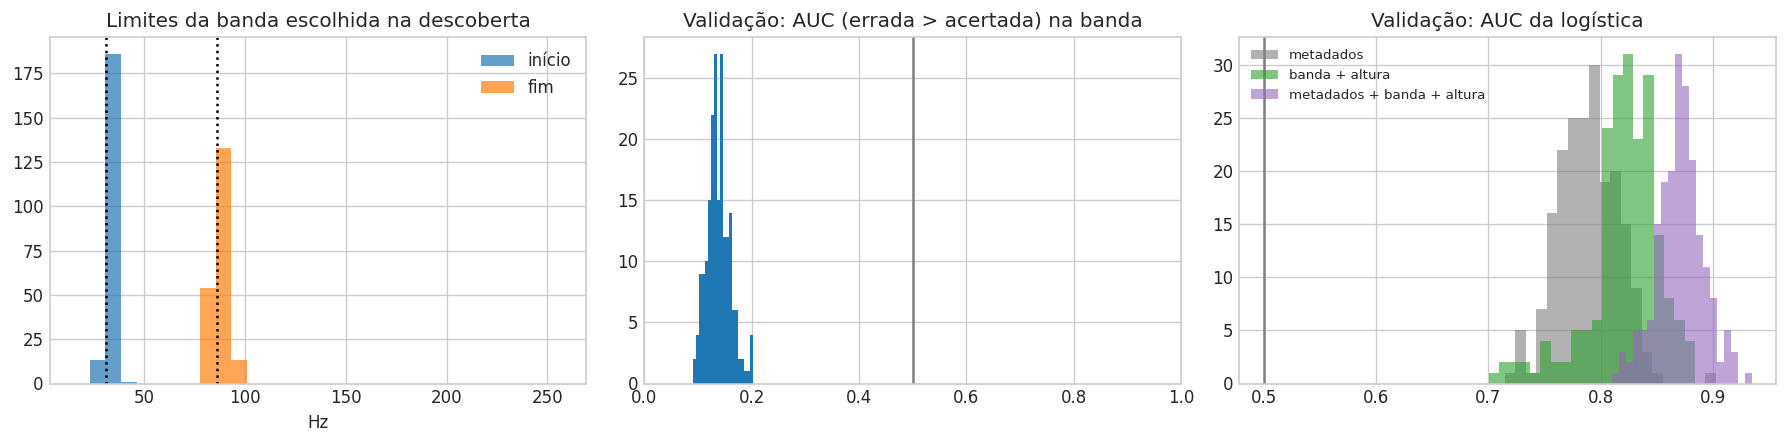

In [18]:
from sklearn.model_selection import StratifiedGroupKFold
from scipy.stats import fisher_exact
# (d) Validação em metades de navios. Em cada divisão, os navios são sorteados em duas metades (estratificadas por ter ou não
# gravação errada). Na metade de DESCOBERTA, a banda é escolhida às cegas pelo mesmo procedimento das Seções 2 e 7:
# teste faixa a faixa por navio + FDR, e a banda é o trecho contíguo de faixas com q < 0,05 e Δ < 0 em torno do menor Δ
# entre 20 e 250 Hz. Na metade de VALIDAÇÃO, que não participou da escolha, medimos o efeito nessa banda.
# 100 sementes × 2 direções (cada metade faz os dois papéis) = 200 divisões.
def faixas_rapido(ids_a, ids_e):
    A, E = por_navio(ids_a), por_navio(ids_e)
    U, p = mannwhitneyu(E.values, A.values, axis=0)
    return E.mean().values - A.mean().values, U / (len(A) * len(E)), false_discovery_control(p)

def escolhe_banda(delta, q):
    cand = np.where((F >= 20) & (F <= 250))[0]
    k0 = cand[np.argmin(delta[cand])]
    sig = (q < 0.05) & (delta < 0)
    if not sig[k0]:
        return None
    a_, b_ = k0, k0
    while a_ > 0 and sig[a_ - 1] and F[a_ - 1] >= 20:
        a_ -= 1
    while b_ < len(F) - 1 and sig[b_ + 1]:
        b_ += 1
    return a_, b_

DV = DC.copy()
PRED = ['Length', 'Wind', 'Sea state']
def modelo(num, cat):
    pre = ColumnTransformer([('n', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
                             ('c', OneHotEncoder(handle_unknown='ignore'), cat)])
    return make_pipeline(pre, LogisticRegression(max_iter=2000))

_navios = DV.groupby('Ship ID').errada.max()
_rows, _perfis = [], []
for seed in range(100):
    cv = StratifiedGroupKFold(2, shuffle=True, random_state=seed)
    halves = [_navios.index[te] for _, te in cv.split(_navios.index, _navios.values, groups=_navios.index)]
    for d in (0, 1):
        desc, val = DV[DV['Ship ID'].isin(halves[d])], DV[DV['Ship ID'].isin(halves[1 - d])]
        dl_d, _, q_d = faixas_rapido(desc.index[desc.grupo == 'acertada'], desc.index[desc.grupo == 'errada'])
        dl_v, auc_v, _ = faixas_rapido(val.index[val.grupo == 'acertada'], val.index[val.grupo == 'errada'])
        k = F <= 1000
        r = {'semente': seed, 'direção': d, 'r do perfil Δ (0–1 kHz)': np.corrcoef(dl_d[k], dl_v[k])[0, 1]}
        bb = escolhe_banda(dl_d, q_d)
        if bb is None:
            _rows.append({**r, 'banda achada': False}); continue
        lo, hi = F[bb[0]], F[bb[1]]
        kb = (F >= lo) & (F <= hi)
        # efeito na validação: LOFAR médio na banda, média por navio em cada grupo (navio misto entra nos dois)
        ba =S.loc[val.index[val.grupo == 'acertada'], kb].mean(1).groupby(val['Ship ID']).mean()
        be = S.loc[val.index[val.grupo == 'errada'], kb].mean(1).groupby(val['Ship ID']).mean()
        U, p = mannwhitneyu(be, ba)
        # pico grave dentro da banda escolhida
        dentro = lambda x: ((x['f pico (Hz)'] >= lo) & (x['f pico (Hz)'] <= hi))
        desc = desc.assign(banda_d=dentro(desc).astype(float)); val = val.assign(banda_d=dentro(val).astype(float))
        pa, pe = val[val.grupo == 'acertada'].banda_d, val[val.grupo == 'errada'].banda_d
        # regressão logística treinada na descoberta, avaliada na validação
        aucs = {}
        for nome, (num, cat) in {'banda + altura': (['banda_d', 'altura (dB)'], []),
                                 'metadados': (PRED, ['Dataset', 'SHIPTYPE']),
                                 'metadados + banda + altura': (PRED + ['banda_d', 'altura (dB)'], ['Dataset', 'SHIPTYPE'])}.items():
            m = modelo(num, cat).fit(desc[num + cat], desc.errada)
            aucs[f'AUC logística: {nome}'] = roc_auc_score(val.errada, m.predict_proba(val[num + cat])[:, 1])
        _rows.append({**r, 'banda achada': True, 'banda: início (Hz)': lo, 'banda: fim (Hz)': hi,
                      'Δ na banda (dB)': be.mean() - ba.mean(), 'AUC na banda': U / (len(ba) * len(be)), 'p na banda': p,
                      '% acertada com pico na banda': 100 * pa.mean(), '% errada com pico na banda': 100 * pe.mean(),
                      'p Fisher': fisher_exact([[pe.sum(), len(pe) - pe.sum()], [pa.sum(), len(pa) - pa.sum()]])[1], **aucs})
VAL = pd.DataFrame(_rows)
N_DIV, N_ACHOU = len(VAL), int(VAL['banda achada'].sum())
V = VAL[VAL['banda achada']]
print(f'{N_DIV} divisões; banda achada na descoberta em {N_ACHOU}')
RESUMO_VAL = V.drop(columns=['semente', 'direção', 'banda achada']).describe(percentiles=[0.05, 0.5, 0.95]).T[['5%', '50%', '95%']]
RESUMO_VAL.columns = ['percentil 5', 'mediana', 'percentil 95']
display(RESUMO_VAL.round(3))
FRAC_P = {'p na banda < 0,05': 100 * (V['p na banda'] < 0.05).mean(), 'p Fisher < 0,05': 100 * (V['p Fisher'] < 0.05).mean()}
print('% das divisões com efeito significativo na validação:', {k: round(v, 1) for k, v in FRAC_P.items()})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(V['banda: início (Hz)'], bins=np.arange(15, 120, FS / NFFT), alpha=0.7, label='início')
ax[0].hist(V['banda: fim (Hz)'], bins=np.arange(15, 260, FS / NFFT), alpha=0.7, label='fim')
ax[0].axvline(31, color='k', ls=':'); ax[0].axvline(86, color='k', ls=':')
ax[0].set_xlabel('Hz'); ax[0].set_title('Limites da banda escolhida na descoberta'); ax[0].legend()
ax[1].hist(V['AUC na banda'], bins=20, color='tab:blue'); ax[1].axvline(0.5, color='gray')
ax[1].set_title('Validação: AUC (errada > acertada) na banda'); ax[1].set_xlim(0, 1)
for c, cor in (('AUC logística: metadados', 'tab:gray'), ('AUC logística: banda + altura', 'tab:green'),
               ('AUC logística: metadados + banda + altura', 'tab:purple')):
    ax[2].hist(V[c], bins=20, alpha=0.6, color=cor, label=c.replace('AUC logística: ', ''))
ax[2].axvline(0.5, color='gray'); ax[2].set_title('Validação: AUC da logística'); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Leitura.**
- **A banda é encontrada em todas as divisões** (200 de 200) e quase sempre no mesmo lugar: 31,2–85,9 Hz em 122 divisões; 31,2–78,1 Hz em 51 divisões; 31,2–93,8 Hz em 13 divisões. Os limites das Seções 2 e 7 (31–86 Hz) são os mais frequentes.
- **O perfil de diferença se repete entre metades:** a correlação do Δ(f) de 0 a 1 kHz entre descoberta e validação tem mediana 0,96 (percentis 5–95: 0,93 a 0,98).
- **Na validação, o efeito se mantém:** Δ na banda com mediana -4,29 (percentis 5–95: -4,99 a -3,57) dB e AUC com mediana 0,14 (percentis 5–95: 0,10 a 0,17); p < 0,05 em 100% das divisões. O Δ é um pouco menor que o da Seção 2 (-6,4 dB na faixa de maior diferença), como esperado: lá era o máximo de uma faixa, aqui é a média da banda inteira.
- **Pico grave na banda:** 88% das acertadas contra 34% das erradas (medianas; Fisher com p < 0,05 em 100% das divisões).
- **Logística treinada numa metade e testada na outra:** banda + altura com mediana 0,82 (percentis 5–95: 0,75 a 0,86); metadados com mediana 0,79 (percentis 5–95: 0,75 a 0,83); tudo junto com mediana 0,87 (percentis 5–95: 0,83 a 0,91). Os valores batem com os da Seção 10.4, então o otimismo de escolher a banda nos mesmos dados era pequeno.
- **O achado se replica em navios novos.** A banda grave não é um artefato de ter procurado em 1024 faixas: ela é escolhida às cegas numa metade e confirmada na outra.

## 12. (e) Banda larga ou raias? LOFAR com faixas de 1 Hz (lofar1hz)

Com faixas de 7,8 Hz, uma banda larga e um conjunto de raias próximas ficam iguais. A extração **lofar1hz** (`scripts/extrair_lofar1hz.py`, `data/iara_processed/lofar1hz/`) refaz o LOFAR só para baixa frequência:
- decimação de 48 kHz para 2 kHz;
- FFT de 2048 pontos, ou seja, janelas de 1,024 s e **faixas de 0,98 Hz** (8 vezes mais finas);
- uma linha a cada 0,512 s (50% de sobreposição), o mesmo passo do LOFAR do pipeline;
- TPSW com **a mesma largura em Hz** do pipeline (±164 Hz), para a banda não virar "fundo".
Usamos 0–300 Hz; acima de ~900 Hz há aliasing.

### 12.1 O espectro médio com 1 Hz

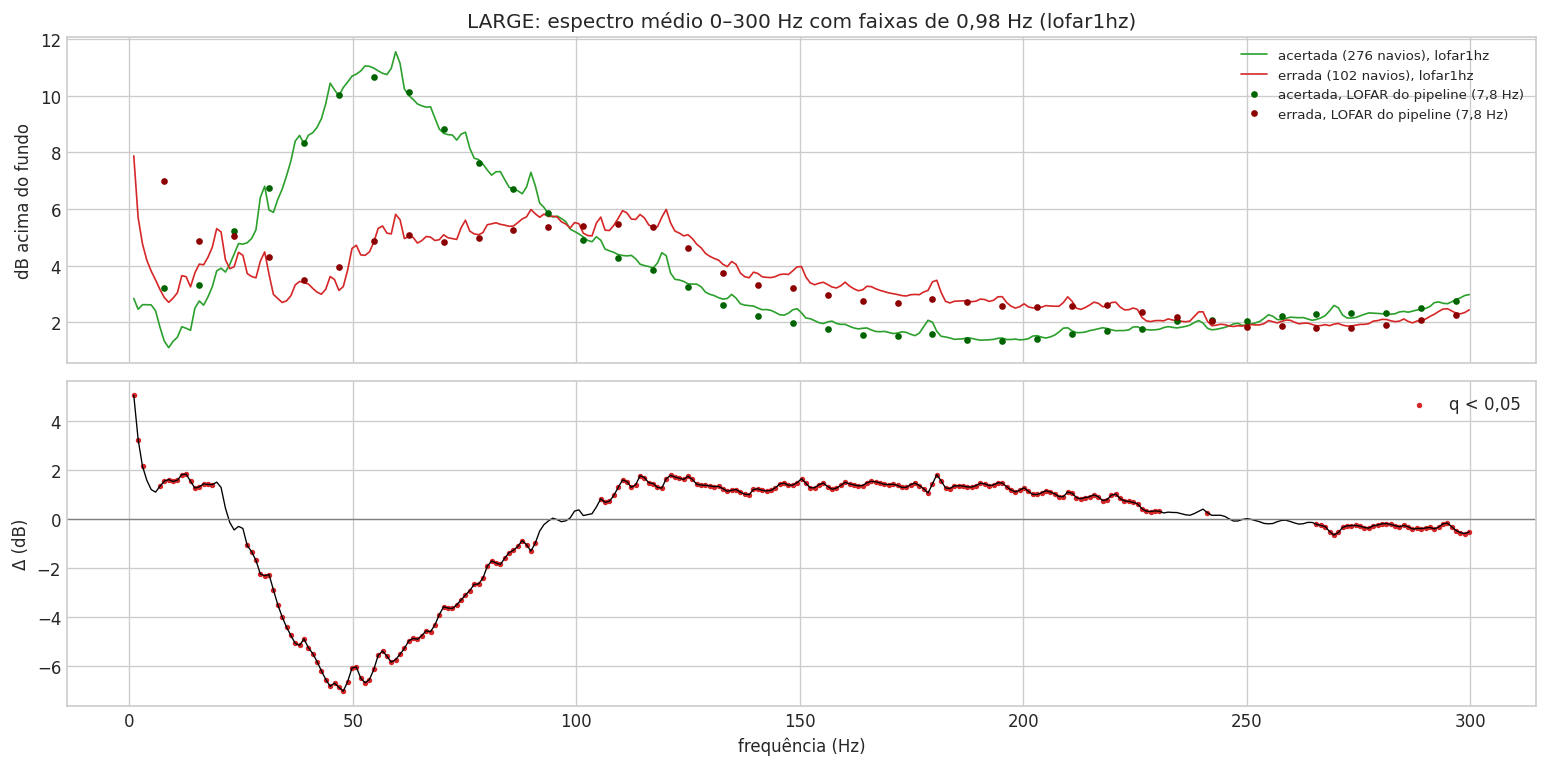

Maior Δ: -7.03 dB em 47.9 Hz (AUC 0.10); pico do espectro médio das acertadas em 59.6 Hz


In [19]:
from scipy.ndimage import median_filter
from scipy.signal import find_peaks, peak_widths
# lofar1hz (scripts/extrair_lofar1hz.py): 48 kHz -> 2 kHz, FFT de 2048 pontos (1,024 s), faixas de 0,977 Hz até 1 kHz,
# TPSW com a mesma largura em Hz do pipeline (±164 Hz). Resumo por gravação: espectro médio e persistência > 6 dB.
R1 = pd.read_pickle(os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar1hz_resumo.pkl'))
F1 = np.asarray(R1['freqs']); S1 = R1['lofar_medio'].astype(float); P1 = R1['pers6'].astype(float); DF1 = F1[0]
IA, IE = T.index[T.grupo == 'acertada'], T.index[T.grupo == 'errada']
def por_navio_1hz(X, ids):
    return X.loc[ids].groupby(T.loc[ids, 'Ship ID'].values).mean()
A1, E1 = por_navio_1hz(S1, IA), por_navio_1hz(S1, IE)
k3 = F1 <= 300
_U, _p = mannwhitneyu(E1.values[:, k3], A1.values[:, k3], axis=0)
TF1 = pd.DataFrame({'f (Hz)': F1[k3], 'acertada': A1.values[:, k3].mean(0), 'errada': E1.values[:, k3].mean(0),
                    'AUC': _U / (len(A1) * len(E1)), 'q (FDR)': false_discovery_control(_p)})
TF1['Δ (errada − acertada)'] = TF1.errada - TF1.acertada

fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
ax[0].plot(TF1['f (Hz)'], TF1.acertada, color='tab:green', lw=1, label=f'acertada ({len(A1)} navios), lofar1hz')
ax[0].plot(TF1['f (Hz)'], TF1.errada, color='tab:red', lw=1, label=f'errada ({len(E1)} navios), lofar1hz')
k7 = F <= 300
ax[0].plot(F[k7], G['acertada'].mean().values[k7], 'o', ms=3, color='darkgreen', label='acertada, LOFAR do pipeline (7,8 Hz)')
ax[0].plot(F[k7], G['errada'].mean().values[k7], 'o', ms=3, color='darkred', label='errada, LOFAR do pipeline (7,8 Hz)')
ax[0].set_ylabel('dB acima do fundo'); ax[0].legend(fontsize=8)
ax[0].set_title(f'{CLASSE}: espectro médio 0–300 Hz com faixas de 0,98 Hz (lofar1hz)')
ax[1].plot(TF1['f (Hz)'], TF1['Δ (errada − acertada)'], color='k', lw=0.8)
s_ = TF1['q (FDR)'] < 0.05
ax[1].scatter(TF1['f (Hz)'][s_], TF1['Δ (errada − acertada)'][s_], s=5, color='tab:red', label='q < 0,05')
ax[1].axhline(0, color='gray', lw=0.8); ax[1].set_ylabel('Δ (dB)'); ax[1].set_xlabel('frequência (Hz)'); ax[1].legend()
plt.tight_layout(); plt.show()
_i = TF1['Δ (errada − acertada)'].idxmin()
L1_MIN = TF1.loc[_i]; L1_PICO = TF1['f (Hz)'][TF1.acertada.idxmax()]
print(f"Maior Δ: {L1_MIN['Δ (errada − acertada)']:.2f} dB em {L1_MIN['f (Hz)']:.1f} Hz (AUC {L1_MIN['AUC']:.2f}); "
      f"pico do espectro médio das acertadas em {L1_PICO:.1f} Hz")

**Leitura.** O lofar1hz reproduz o LOFAR do pipeline (os pontos ficam sobre as curvas), agora com detalhe de 1 Hz. O pico médio das acertadas fica em 59,6 Hz e a maior diferença é -7,0 dB em 47,9 Hz (AUC = 0,10); 249 das 307 faixas entre 0 e 300 Hz têm q < 0,05. A diferença continua sendo uma **corcova larga**, sem picos estreitos que se destaquem só num dos grupos.

### 12.2 Separando a componente larga das raias

Em cada gravação, o espectro médio de 31–86 Hz é separado em uma **componente larga** (mediana móvel de ~15 Hz, que ignora estruturas mais estreitas que ~7 Hz) e **raias** (máximos locais que sobem pelo menos 3 dB acima dela). A comparação entre grupos é feita por navio:

31–86 Hz, por navio (Mann-Whitney):


,mediana acertada,mediana errada,AUC (errada > acertada),p
medida,,,,
componente larga (dB),8.47,3.78,0.12,0.00e+00
energia das raias (dB),0.40,0.47,0.53,4.00e-01
raias (n),2.00,2.00,0.51,7.43e-01
altura das raias (dB),3.41,3.96,0.60,9.00e-03


Controle 150–205 Hz: 0.28 raias por gravação nas acertadas e 0.51 nas erradas


Sensibilidade (AUC por navio; 0,5 = sem diferença):


,mediana móvel (faixas),proeminência (dB),AUC componente larga,AUC energia das raias,AUC nº de raias
0,11,2.0,0.12,0.54,0.48
1,11,3.0,0.12,0.54,0.51
2,11,6.0,0.12,0.54,0.51
3,15,2.0,0.12,0.53,0.47
4,15,3.0,0.12,0.53,0.51
5,15,6.0,0.12,0.53,0.51
6,21,2.0,0.12,0.51,0.47
7,21,3.0,0.12,0.51,0.51
8,21,6.0,0.12,0.51,0.53


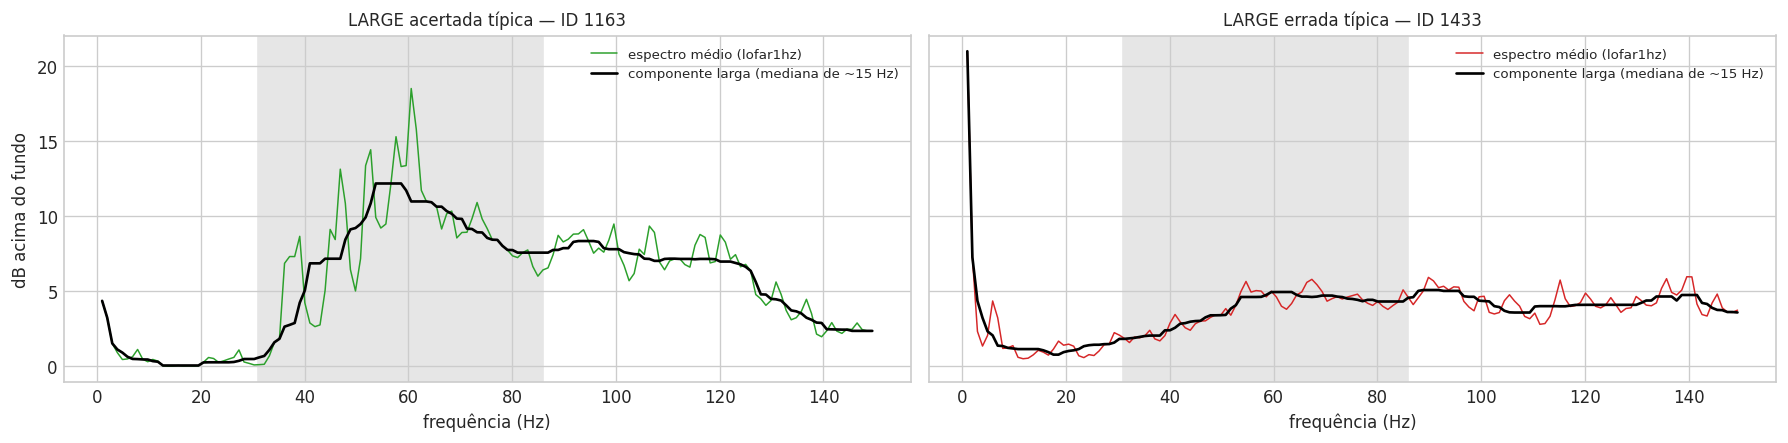

In [20]:
# Banda larga ou raias? Em cada gravação, o espectro médio (lofar1hz) é separado em:
#   componente larga = mediana móvel de 15 faixas (~15 Hz): ignora estruturas mais estreitas que ~7 Hz;
#   raias = o que sobe acima dela; uma raia é um máximo local com proeminência >= 3 dB.
# Num espectro médio de ~580 linhas, a flutuação do ruído é de décimos de dB: 3 dB é uma raia estável, não ruído.
def decompoe(i, lo=31, hi=86, jan=15, prom=3.0):
    y = S1.loc[i].values
    base = median_filter(y, size=jan, mode='nearest')
    r = y - base
    k = (F1 >= lo) & (F1 <= hi)
    pk, _ = find_peaks(r, prominence=prom); pk = pk[k[pk]]
    return {'componente larga (dB)': base[k].mean(), 'energia das raias (dB)': np.clip(r[k], 0, None).mean(),
            'raias (n)': len(pk), 'altura das raias (dB)': r[pk].mean() if len(pk) else np.nan}

def compara(Dx):
    rows = []
    for c in ('componente larga (dB)', 'energia das raias (dB)', 'raias (n)', 'altura das raias (dB)'):
        sh = Dx.groupby(['Ship ID', 'grupo'])[c].mean().unstack()
        a, e = sh['acertada'].dropna(), sh['errada'].dropna()
        U, p = mannwhitneyu(e, a)
        rows.append({'medida': c, 'mediana acertada': a.median(), 'mediana errada': e.median(),
                     'AUC (errada > acertada)': U / (len(a) * len(e)), 'p': p})
    return pd.DataFrame(rows).set_index('medida')

_ids = list(IA) + list(IE)
def tabela(lo=31, hi=86, jan=15, prom=3.0):
    Dx = pd.DataFrame({i: decompoe(i, lo, hi, jan, prom) for i in _ids}).T.astype(float)
    return Dx.join(T[['grupo', 'Ship ID']])
DEC = tabela()
DEC_CMP = compara(DEC)
print('31–86 Hz, por navio (Mann-Whitney):'); display(DEC_CMP.round(3))
DEC_CTRL = tabela(150, 205)
print(f"Controle 150–205 Hz: {DEC_CTRL.loc[IA, 'raias (n)'].mean():.2f} raias por gravação nas acertadas e "
      f"{DEC_CTRL.loc[IE, 'raias (n)'].mean():.2f} nas erradas")

# sensibilidade: largura da mediana móvel e proeminência mínima
_rows = []
for jan in (11, 15, 21):
    for prom in (2.0, 3.0, 6.0):
        c = compara(tabela(jan=jan, prom=prom))['AUC (errada > acertada)']
        _rows.append({'mediana móvel (faixas)': jan, 'proeminência (dB)': prom, 'AUC componente larga': c['componente larga (dB)'],
                      'AUC energia das raias': c['energia das raias (dB)'], 'AUC nº de raias': c['raias (n)']})
DEC_SENS = pd.DataFrame(_rows)
print('Sensibilidade (AUC por navio; 0,5 = sem diferença):'); display(DEC_SENS.round(3))

# exemplo visual: a acertada e a errada mais típicas (mais perto da mediana da componente larga do seu grupo)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8), sharey=True)
for a_, g, cor in ((ax[0], 'acertada', 'tab:green'), (ax[1], 'errada', 'tab:red')):
    x = DEC[DEC.grupo == g]['componente larga (dB)']
    i = (x - x.median()).abs().idxmin()
    k = F1 <= 150
    y = S1.loc[i].values; base = median_filter(y, size=15, mode='nearest')
    a_.plot(F1[k], y[k], color=cor, lw=0.9, label='espectro médio (lofar1hz)')
    a_.plot(F1[k], base[k], color='k', lw=1.6, label='componente larga (mediana de ~15 Hz)')
    a_.axvspan(31, 86, color='0.9', zorder=0)
    a_.set_title(f'{CLASSE} {g} típica — ID {i}', fontsize=10); a_.set_xlabel('frequência (Hz)'); a_.legend(fontsize=8)
ax[0].set_ylabel('dB acima do fundo'); plt.tight_layout(); plt.show()

**Leitura.**
- Componente larga: mediana 8,47 nas acertadas × 3,78 nas erradas (AUC = 0,12, p < 0,001).
- Energia das raias: mediana 0,40 nas acertadas × 0,47 nas erradas (AUC = 0,53, p = 0,400).
- Número de raias: mediana 2,00 nas acertadas × 2,00 nas erradas (AUC = 0,51, p = 0,743).
- Altura média das raias: mediana 3,41 nas acertadas × 3,96 nas erradas (AUC = 0,60, p = 0,009).
- A altura das raias sobre a componente larga é um pouco maior nas erradas (4,0 × 3,4 dB): sem a banda forte por baixo, as mesmas raias se destacam um pouco mais. O efeito é pequeno perto do da componente larga.
- Na faixa de controle 150–205 Hz há 0,28 raias por gravação nas acertadas e 0,51 nas erradas: as raias de 31–86 Hz são de fato uma estrutura da região grave.
- **Sensibilidade:** com mediana móvel de 11, 15 ou 21 faixas e proeminência de 2, 3 ou 6 dB, a AUC da componente larga fica entre 0,12 e 0,12; a da energia das raias, entre 0,51 e 0,54; a do número de raias, entre 0,47 e 0,53.
- **O que separa acertadas de erradas é a componente larga, não as raias.** As duas têm raias estreitas em 31–86 Hz em número e energia parecidos (no exemplo acertado acima, elas aparecem sobre a banda); nas acertadas, essas raias ficam sobre uma componente larga forte, que nas erradas é fraca. A diferença que os modelos aproveitam é, portanto, **principalmente de banda larga** de baixa frequência, e não um conjunto de raias que o LOFAR do pipeline não resolvia (fontes candidatas: hélice e escoamento em torno do casco; não verificado).
- **Limite:** raias espaçadas de menos de ~2 Hz (por exemplo, harmônicos de um eixo a 60–120 rpm) ainda se fundiriam com faixas de 1 Hz e janela de Hanning. Um "pente" muito fino continuaria parecendo banda larga.

### 12.3 Raias estreitas abaixo de 31 Hz

Nos espectrogramas com 1 Hz aparecem raias finas e estáveis abaixo de 30 Hz, que o LOFAR do pipeline não resolve. Elas diferem entre acertadas e erradas?

,% gravações acertadas com raia,% gravações erradas com raia,raias por gravação (acertada),raias por gravação (errada),"p (Fisher, por navio)"
faixa,,,,,
5–31 Hz,36.70,41.88,0.58,0.65,0.81
31–86 Hz,41.33,48.72,1.14,0.97,0.06
86–300 Hz,33.24,41.03,0.65,0.93,0.14


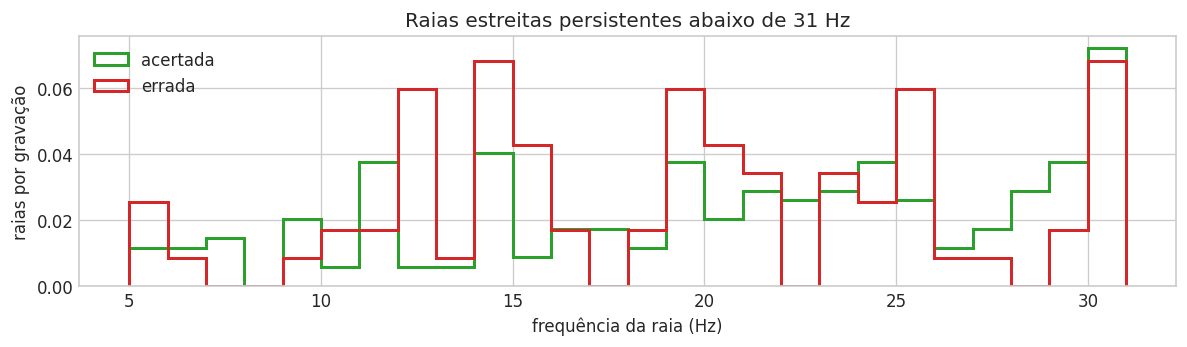

In [21]:
# Raias estreitas e persistentes: máximo local da persistência > 6 dB com >= 50% das janelas, que se destaca pelo menos
# 20 pontos percentuais dos vizinhos (proeminência >= 0,2; sem isso, ondulações sobre a banda larga contariam como raias)
# e tem largura a meia proeminência <= 3 Hz. Abaixo de 31 Hz, o fundo TPSW só tem vizinhos de um lado e inclui a banda
# grave: leia com cautela.
import warnings
warnings.filterwarnings('ignore', message='some peaks have')   # picos na borda do eixo têm largura 0; são descartados
def estreitas(i, lo, hi):
    y = P1.loc[i].values
    pk, _ = find_peaks(np.r_[0, y, 0], height=0.5, prominence=0.2); pk = pk - 1
    if len(pk) == 0:
        return np.array([])
    w = peak_widths(y, pk, rel_height=0.5)[0] * DF1
    f = F1[pk]
    return f[(w <= 3) & (f >= lo) & (f < hi)]
_rows = []
for lo, hi in ((5, 31), (31, 86), (86, 300)):
    L = {i: estreitas(i, lo, hi) for i in _ids}
    tem = pd.Series({i: len(v) > 0 for i, v in L.items()})
    na = tem[IA].groupby(T.loc[IA, 'Ship ID'].values).max(); ne = tem[IE].groupby(T.loc[IE, 'Ship ID'].values).max()
    _rows.append({'faixa': f'{lo}–{hi} Hz', '% gravações acertadas com raia': 100 * tem[IA].mean(),
                  '% gravações erradas com raia': 100 * tem[IE].mean(),
                  'raias por gravação (acertada)': np.mean([len(L[i]) for i in IA]),
                  'raias por gravação (errada)': np.mean([len(L[i]) for i in IE]),
                  'p (Fisher, por navio)': fisher_exact([[ne.sum(), len(ne) - ne.sum()], [na.sum(), len(na) - na.sum()]])[1]})
    if lo == 5:
        FB_A = np.concatenate([L[i] for i in IA]); FB_E = np.concatenate([L[i] for i in IE])
BAIXAS = pd.DataFrame(_rows).set_index('faixa')
display(BAIXAS.round(3))
fig, ax = plt.subplots(figsize=(10, 3))
bins = np.arange(5, 31.5, 1)
ax.hist(FB_A, bins=bins, histtype='step', lw=1.8, color='tab:green', weights=np.full(len(FB_A), 1 / len(IA)), label='acertada')
ax.hist(FB_E, bins=bins, histtype='step', lw=1.8, color='tab:red', weights=np.full(len(FB_E), 1 / len(IE)), label='errada')
ax.set_xlabel('frequência da raia (Hz)'); ax.set_ylabel('raias por gravação'); ax.legend()
ax.set_title('Raias estreitas persistentes abaixo de 31 Hz'); plt.tight_layout(); plt.show()

**Leitura.**
- Têm ao menos uma raia estreita persistente entre 5 e 31 Hz 37% das acertadas e 42% das erradas (Fisher por navio, p = 0,814). **As raias graves não distinguem os grupos**: aparecem nos dois, em frequências espalhadas.
- O mesmo critério em 31–86 Hz dá 41% × 49% (p = 0,061) e em 86–300 Hz, 33% × 41% (p = 0,145). As raias estreitas persistentes não favorecem as acertadas em nenhuma região, coerente com a Seção 12.2.
- Abaixo de 31 Hz o fundo TPSW é estimado só do lado de cima e inclui a banda grave, então esses valores são os menos confiáveis do espectro.

## 13. Conclusões parciais e próximos passos

1. **Frequência comum às LARGE acertadas:** uma banda de baixa frequência em ~31–86 Hz (pico médio em 55 Hz); 88% delas têm o pico grave em 31–86 Hz. As LARGE erradas têm o pico grave em outras frequências, com distribuição parecida com a de MEDIUM e SMALL, e no espectro médio se parecem com SMALL.
2. **Subconjunto de gravação:** a diferença aparece dentro de cada subconjunto testado. **Modelo:** o perfil se repete no consenso CNN + MLP + SVM.
3. **É uma banda, não uma raia:** largura mediana de 55 Hz e nenhuma estrutura harmônica acima do acaso. Com 7,8 Hz não dava para separar banda larga de raias próximas; o item 8 responde com faixas de 1 Hz.
4. **A banda é uma pista importante para o modelo dizer LARGE, mas fraca de tamanho real:** com a banda, a chance de ser chamada de LARGE sobe em todas as classes (SMALL de 11% para 37%, LARGE de 39% para 83%), mas ela aparece também em 43% das SMALL e 35% das MEDIUM (Seção 7.1). Dentro das LARGE, o pico fica um pouco mais grave nos navios maiores (ρ = -0,20), mas a relação é fraca.
5. **A banda depende da gravação, não só do navio:** nos 17 navios com gravações nos dois grupos, ela aparece em 81% das gravações acertadas e em 24% das erradas (p = 0,013). Vento e mar agitado reduzem um pouco a banda, mas não explicam sozinhos a sua falta. A explicação mais provável fica no que o IARA não registra: regime de operação (velocidade, carga), distância e propagação. Isso ainda é uma **hipótese**.
6. **Fatores complementares:** a banda sozinha prevê o erro com AUC = 0,82, os metadados com 0,80 e os dois juntos com 0,88.
7. **Validação:** escolhida às cegas numa metade dos navios, a banda é a mesma (31,2–85,9 Hz em 122 divisões) e o efeito se confirma na outra metade em 100% das 200 divisões (AUC mediana 0,14; logística banda + altura 0,82 em navios não vistos).
8. **Banda larga, não raias:** com faixas de 1 Hz (lofar1hz), a diferença entre acertadas e erradas está na componente larga de 31–86 Hz (AUC = 0,12); as raias estreitas dessa região aparecem nos dois grupos em número e energia parecidos. Raias espaçadas de menos de ~2 Hz ainda não seriam resolvidas.

**Próximos passos:** repetir para MEDIUM e SMALL (o lofar1hz já está extraído para todas as gravações).